# Programing 2 Project,  Breast and Lung Cancer

# Environment Setup

Import all required libraries for data processing, model training, and evaluation.

## Libraries used

| Library | Purpose |
|---------|---------|
| `numpy`, `pandas` | Numerical operations and data handling |
| `tensorflow` / `keras` | Deep learning framework — model building and training |
| `mixed_precision` | Float16 training for faster GPU computation |
| `ImageDataGenerator` | Real-time image augmentation during training |
| `compute_class_weight` | Handles class imbalance by weighting minority classes |
| `sklearn` | Evaluation metrics — confusion matrix, classification report |
| `matplotlib` | Plotting training curves and results |
| `os`, `shutil`, `random` | File and folder management |
| `time` | Measuring training and inference duration |

## Notes

- `mixed_precision` uses **float16** for computation and **float32** for
  model outputs, reducing memory usage and speeding up training on
  compatible GPUs (NVIDIA T4, A100, V100).


In [2]:
#Step 1 implementation
#Hint: Take the help of split-folder python library
import numpy as np
import pandas as pd
import os
import random
import shutil
import tensorflow as tf
from tensorflow.keras import mixed_precision
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import regularizers
from sklearn.utils.class_weight import compute_class_weight
import time
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

print("Built with CUDA:", tf.test.is_built_with_cuda())
print(tf.config.list_physical_devices('GPU'))

Built with CUDA: True
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')
print(os.getcwd())

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive
/content


In [4]:
from pathlib import Path

project_path = Path("/content/drive/MyDrive/AIMLP2/com1r1")


In [5]:
os.listdir(project_path)

['DataSet20K.zip',
 'resnet50v2_Head_training.keras',
 'resnet50v2_Head_training.csv',
 'densenet169_Head_training.keras',
 'densenet169_Head_training.csv',
 'resnet50v2_PartialUnfreeze.keras',
 'resnet50v2_PartialUnfreeze.csv',
 'densenet169_PartialUnfreeze.keras',
 'densenet169_PartialUnfreeze.csv',
 'resnet50v2_FullUnfreeze.keras',
 'resnet50v2_FullUnfreeze.csv',
 'densenet169_FullUnfreeze.keras',
 'densenet169_FullUnfreeze.csv',
 'resnet50v2_Tuning.csv',
 'densenet169_Tuning.csv',
 'densenet169_Tuning.keras',
 'resnet50v2_Tuning.keras',
 'LRresnet50v2_Tuning.keras',
 'LRresnet50v2_Tuning.csv',
 'LRdensenet169_Tuning.keras',
 'LRdensenet169_Tuning.csv',
 'resnet50v2_PartialUnfreeze_1e4.keras',
 'resnet50v2_PartialUnfreeze_1e4.csv',
 'resnet50v2_GradUnfreeze_1e41e5.keras',
 'resnet50v2_GradUnfreeze_1e41e5.csv',
 'densenet169_PartialUnfreeze_1e4.keras',
 'densenet169_PartialUnfreeze_1e4.csv',
 'Exp1R1 CNN Models AIMLP2.ipynb']

# Loading the Dataset for Training from the Zip File

## Workflow

At the start of every Colab session, unzip the dataset from Google Drive
directly to Colab's local disk (`/content/`). Local disk reads are
**10-50× faster** than reading directly from Drive during training,
because Drive API adds latency per file request — critical when loading
thousands of image patches per epoch.

| Step | Action |
|------|--------|
| 1 | Mount Google Drive |
| 2 | Unzip dataset from Drive → `/content/` |
| 3 | Point data generators to local paths |

## Why unzip to `/content/`

| | Drive | Local `/content/` |
|--|--|--|
| 🐢 Read speed | Slow | 🚀 Fast |
| ⏱️ Latency per file | High | Low |
| 🚦 Throttling risk | Yes | No |
| 🎮 GPU idle time | High | Low |
| 📁 Survives session reset | Yes | No |
| 💾 Permanent storage | Yes | No |

The 1-3 minute unzip cost at session start is recovered within the first
training epoch.



In [6]:
!rm -rf "/content/train" \
        "/content/val" \
        "/content/test" \
        "/content/DataSet20K.zip"

In [7]:
file_path = project_path / "DataSet20K.zip"

!cp "{file_path}"  "/content/DataSet20K.zip"

!unzip -q -o "/content/DataSet20K.zip" -d "/content/"

In [8]:
base_dir = '/content'
os.listdir(base_dir)

['.config', 'drive', 'val', 'DataSet20K.zip', 'test', 'train', 'sample_data']

Check the directory

In [9]:
train_dir = '/content/train'
test_dir = '/content/test'
val_dir = '/content/val'


for pa in [train_dir,val_dir,test_dir]:
  folder_path=[]
  class_names = [ ]
  n_imgs = []
  for typename in os.listdir(pa):
      folder_path.append (os.path.join(pa, typename))
      n_imgs.append (len(os.listdir(folder_path[-1])))
      class_names.append(typename)
  print (class_names)
  print (n_imgs)
  print(f"The Total Number of images in {os.path.basename(pa)} set are   {sum(n_imgs)}" )
  print ("------------------------------------------------------\n")


['Breast Invasive', 'LUGAD', 'SCC', 'Breast InSitu', 'Breast Benign']
[14000, 14000, 14000, 14000, 14000]
The Total Number of images in train set are   70000
------------------------------------------------------

['Breast Invasive', 'LUGAD', 'SCC', 'Breast InSitu', 'Breast Benign']
[3000, 3000, 3000, 3000, 3000]
The Total Number of images in val set are   15000
------------------------------------------------------

['Breast Invasive', 'LUGAD', 'SCC', 'Breast InSitu', 'Breast Benign']
[3000, 3000, 3000, 3000, 3000]
The Total Number of images in test set are   15000
------------------------------------------------------



##**<font color='blue'>**Data Genrator**</font>**

This Section will include the reprocessing  "Data Augumentation" and Data Normalization.

For this section, we will create 3 Data Genrator for 3 models:

1) Breast Cancer only
2) Lung Cancer Only
3) Breast and Lun Cancer




In [10]:

class_names= ["Breast InSitu","Breast Benign","Breast Invasive","SCC", "LUGAD" ]

BACKBONES = {

     "densenet169": {
        "builder": tf.keras.applications.DenseNet169,
        "preprocess": (
            tf.keras.applications.densenet.preprocess_input
        ),
    },
    "resnet50v2": {
        "builder": tf.keras.applications.ResNet50V2,
        "preprocess": tf.keras.applications.resnet_v2.preprocess_input,
    },
}

def Data_generator(backbone_name, batch_size=32, img_size=(224, 224)):

    print(f"----------- {backbone_name} Training set -----------")
    preprocess_input = BACKBONES[backbone_name]["preprocess"]

    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        labels="inferred",
        label_mode="categorical",
        class_names=["Breast InSitu","Breast Benign","Breast Invasive","SCC", "LUGAD" ],
        image_size=img_size,
        batch_size=None,
        shuffle=True,
        seed=42
    )

    print(f"----------- {backbone_name} Validation set -----------")
    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        labels="inferred",
        label_mode="categorical",
        class_names= ["Breast InSitu","Breast Benign","Breast Invasive","SCC", "LUGAD" ],
        image_size=img_size,
        batch_size=None,
        shuffle=False
    )

    print(f"----------- {backbone_name} Testing set -----------")
    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir,
        labels="inferred",
        label_mode="categorical",
        class_names= ["Breast InSitu","Breast Benign","Breast Invasive","SCC", "LUGAD" ] ,
        image_size=img_size,
        batch_size=None,
        shuffle=False
    )

    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),
        tf.keras.layers.RandomRotation(0.25),        # 180D
        tf.keras.layers.RandomZoom(0.05),
        tf.keras.layers.RandomTranslation(0.05, 0.05),
        tf.keras.layers.RandomContrast(0.05),
        tf.keras.layers.RandomBrightness(0.02),     # ≈ [0.98, 1.02]

    ])



    def train_process(x, y):
        x = augmentation(x, training=True)
        x = preprocess_input(x)
        return x, y

    def val_test_process(x, y):
        x = preprocess_input(x)
        return x, y

    AUTOTUNE = tf.data.AUTOTUNE

    train_ds = train_ds.shuffle(2000).batch(batch_size)
    train_ds= train_ds.map(train_process, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

    val_ds = (val_ds.batch(batch_size).map(val_test_process, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
    test_ds = ( test_ds.batch(batch_size).map(val_test_process, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE) )




    print(f"\n{backbone_name},  Target Classes =", class_names)
    print("----------------------------")

    return train_ds, val_ds, test_ds


* Below code, to genrator Data for the 2 models using the Function above:
1) Data for Resnet_train_generator
2) Data for Densenet169_train_generator

In [11]:
mixed_precision.set_global_policy("mixed_float16")

Resnet_train_generator, Resnet_val_generator, Resnet_test_generator = Data_generator (backbone_name = "resnet50v2", batch_size=64, img_size=(224, 224)  )
Densenet_train_generator, Densenet_val_generator, Densenet_test_generator = Data_generator (backbone_name = "densenet169" , batch_size=64, img_size=(224, 224)  )

----------- resnet50v2 Training set -----------
Found 70000 files belonging to 5 classes.
----------- resnet50v2 Validation set -----------
Found 15000 files belonging to 5 classes.
----------- resnet50v2 Testing set -----------
Found 15000 files belonging to 5 classes.

resnet50v2,  Target Classes = ['Breast InSitu', 'Breast Benign', 'Breast Invasive', 'SCC', 'LUGAD']
----------------------------
----------- densenet169 Training set -----------
Found 70000 files belonging to 5 classes.
----------- densenet169 Validation set -----------
Found 15000 files belonging to 5 classes.
----------- densenet169 Testing set -----------
Found 15000 files belonging to 5 classes.

densenet169,  Target Classes = ['Breast InSitu', 'Breast Benign', 'Breast Invasive', 'SCC', 'LUGAD']
----------------------------


---
---

#**<font color='blue'>** The Funtions will be used for all models **</font>**



## 1. Model Architecture

Transfer learning model pre-trained on ImageNet, adapted for histopathology
patch classification.

```
Input (224 × 224 × 3)
        ↓
ResNet50V2 / DenseNet169
        ↓
GlobalAveragePooling2D
        ↓
Dense → Dropout → Softmax
        ↓
Output (num_class probabilities)
```

| Parameter | Purpose |
|-----------|---------|
| `num_class` | Number of output classes ( 5) |
| `dense` | Hidden layer size 256 — larger for harder tasks |
| `drop` | Dropout rate 0.5 — regularization strength |



##2. Model Training Function

Handles both **Stage 1** (head only) and **Stage 2** (fine-tuning) training
through a single reusable function.

## Training stages

| Stage | `train_layer` | Learning rate | Purpose |
|-------|--------------|---------------|---------|
| Stage 1 | `"N"` | `1e-3` | Train classification head only — backbone frozen |
| Stage 2 | `Fine Tuned All layers"` | `1e-5` | Fine-tune backbone layers — adapts features to histopathology |

## Callbacks

| Callback | Behaviour |
|----------|-----------|
| `EarlyStopping` | Stops training when `val_loss` stops improving — restores best weights |
| `ReduceLROnPlateau` | Halves learning rate after 3 epochs without improvement — minimum `1e-7` |

##3. Model Evaluation Function

Provides a comprehensive evaluation of a trained CNN model on the test set,
reporting four key metrics:

| Metric | What it measures |
|--------|-----------------|
| **Accuracy** | Overall fraction of correctly classified patches |
| **Confusion matrix** | Per-class correct and incorrect predictions |
| **Classification report** | Precision, recall, and F1-score per class |
| **Macro AUC** | Discrimination ability across all classes |

## Why these four metrics

**Accuracy alone is not enough** for medical image classification:

- A model predicting only the majority class can achieve high accuracy
  while completely failing on rare classes
- **Precision and recall** reveal per-class performance — critical when
  misclassifying cancer subtypes has different clinical consequences
- **AUC** measures how well the model separates classes regardless of
  threshold — more informative than accuracy for imbalanced datasets
- **Confusion matrix** shows exactly which classes are being confused
  with each other, guiding further improvements

## Outputs

```
1. Overall test accuracy (from model.evaluate)
2. Inference time — total and per-sample (ms)
3. Confusion matrix — visual heatmap
4. Classification report — precision / recall / F1 per class
5. Macro AUC (one-vs-rest) — overall discrimination score
```

In [12]:
# Create Backbone ResNet50 with Freezed layers,  the return will be the model and

class Build_model:

  def __init__(self, backbone_name, dense_layer=256, dropout=0.5):
      self.backbone_name = backbone_name
      self.dense_layer= dense_layer
      self.dropout = dropout
      self.num_classes = 5
      self.model_target_names = ["Breast InSitu","Breast Benign","Breast Invasive","SCC", "LUGAD" ]
      self.history_head = {}
      self.history_tune = {}
      self.history_all = {}
      self.model = self.model_base()


  def model_base(self):
    build_backbone = BACKBONES[self.backbone_name]["builder"]
    base = build_backbone(weights="imagenet",include_top=False,input_shape=(224, 224, 3))
    base.trainable = False
    inputs = tf.keras.layers.Input(shape=(224, 224, 3))

    feature_maps  = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(feature_maps )
    x = tf.keras.layers.Dense(self.dense_layer, activation="relu")(x)                    # ,kernel_regularizer=regularizers.l2(1e-4)
    x = tf.keras.layers.Dropout(self.dropout)(x)
    outputs = tf.keras.layers.Dense(self.num_classes, activation="softmax", dtype="float32" )(x)
    model = tf.keras.Model(inputs, outputs)
    self.cam_model = tf.keras.Model(inputs,[feature_maps, outputs])
    return model

  def training (self, training, validation, file_dis , early_stop_patient= 8, learning_rate = 0.001, N_Epochs  =70):
    # setting
    start_time = time.time()
    early_stopping = tf.keras.callbacks.EarlyStopping (
        monitor='val_loss',
        patience= early_stop_patient,             # Stop if no improvement for 10 epochs
        restore_best_weights=True )               # Go back to best model weights )

    RLR = tf.keras.callbacks.ReduceLROnPlateau(
                    monitor  = 'val_loss',
                    factor   = 0.5,
                    patience = 4,               # reduce lr quickly when val_loss rises                     7 before
                    cooldown=1,
                    min_lr   = 1e-7  )
    device = ("/GPU:0" if tf.config.list_physical_devices("GPU") else "/CPU:0")
    print(device)

    # Compile
    with tf.device(device):
      self.model.compile(
          optimizer = tf.keras.optimizers.Adam(learning_rate),
          loss      = tf.keras.losses.CategoricalCrossentropy(),
          metrics=["accuracy"])

      history = self.model.fit(
          training,
          epochs          = N_Epochs,
          validation_data = validation,
          callbacks=[early_stopping ,RLR] )

    # Save Model
    save_path = project_path / f"{file_dis}.keras"
    self.model.save(save_path)

    end_time = time.time()
    print (f"Training Time is {((end_time-start_time)/60):.2f} min")
    return history.history


  def head_training (self, training, validation , early_stop_patient= 8, learning_rate = 0.001, N_Epochs  = 70 ):

      file_dis = f"{self.backbone_name}_Head_training"

      #stage2  unfreeze layer and finetune the layers, with lower learning rate to not affect the backbone
      print("----------- Training --------------")
      self.model.summary()

      # Call Training Method
      self.history_head = self.training(training, validation, file_dis , early_stop_patient, learning_rate , N_Epochs)

      # Call Saving Training History Method
      self.save_history(self.history_head, file_dis)          # Just Save history as CSV



  def tuning (self, training, validation,  early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70 ):
    #stage2  unfreeze layer and finetune the layers, with lower learning rate to not affect the backbone

    file_dis = f"{self.backbone_name}_Tuning"
    print("----------- Training --------------")
    #if train_layer == "N":
    #    pass
    #else:
    base = self.model.layers[1]         # The backbone
    for layer in base.layers[0:]:
      if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
      else:
        layer.trainable = True

    self.model.summary()

    # Call Training and get history
    self.history_tune = self.training(training, validation, file_dis , early_stop_patient, learning_rate , N_Epochs)

    # Save History
    self.save_history(self.history_tune,file_dis )   # Just Save history as CSV

    # Combined Head and tuned history
    combine_histories ={}
    for hist in [self.history_head, self.history_tune ]:
        for key, values in hist.items():
            if key not in combine_histories:
                combine_histories[key] = []
            combine_histories[key].extend(values)

    self.history_all = combine_histories



  def save_history(self, history_data, dis):
    df = pd.DataFrame(history_data)           #  Covert the history to Dataframe to save it as CVS
    df.index.name = 'epoch'
    df_save_path = project_path / f"{dis}.csv"
    df.to_csv(df_save_path)


  # Function for check Model Peformance and Confusion matrix
  def evaluate(self, test_ds ):
      print("============================================================")
      print(" MODEL EVALUATION")
      print("  Model Accuracy for Testing Set = " )
      self.model.evaluate(test_ds)
      print ("\n---------------------------------------------------------  \n\n")

      start_time = time.time()
      true_list = []
      prediction_list = []

      # Make prediction
      predicted_probabilities = self.model.predict(test_ds, verbose=1)

      prediction_list = np.argmax (predicted_probabilities, axis=1)  # verbose=1  # Progress bar,  Axis 1, coloum referance
      for images, labels in test_ds:
              true_list.append(np.argmax(labels.numpy(), axis=1))
      true_list = np.concatenate(true_list, axis=0)             # make it one list



      # Time for evaluation
      end_time = time.time()
      time_sec = end_time - start_time
      num_samples = len(true_list)
      mean_time_ms = (time_sec / num_samples) * 1000
      print(f"Total inference time: {time_sec:.2f}s for {num_samples} samples")
      print(f"Mean time per sample: {mean_time_ms:.2f} ms")
      print("\n---------------------------------------------------------\n\n")

      # confidence Calculation
      confidence = np.max(predicted_probabilities, axis=1)        # this get the max probabilty only
      correct = prediction_list == true_list
      conf_count = [ correct.sum(),
                    (correct & (confidence >= 0.90)).sum(),
                    (correct & (confidence >= 0.80) & (confidence < 0.90)).sum(),
                    (correct & (confidence >= 0.70) & (confidence < 0.80)).sum(),
                    (correct & (confidence >= 0.50) & (confidence < 0.70)).sum(),
                    (correct & (confidence < 0.50)).sum()]


      print("Correct predictions:", conf_count[0], "/", len(true_list), f"--({(conf_count[0] / len(true_list)) :.2%}) " )
      print("Number of correct predictions above 90% confidence  :", conf_count[1],  f"--({( conf_count[1]/conf_count[0] ):.2%}) "  )
      print("Number of correct predictions    80-90% confidence  :", conf_count[2],  f"--({( conf_count[2]/conf_count[0] ):.2%}) "  )
      print("Number of correct predictions    70-80% confidence  :", conf_count[3],  f"--({( conf_count[3]/conf_count[0] ):.2%}) "  )
      print("Number of correct predictions    50-70% confidence  :", conf_count[4],  f"--({( conf_count[4]/conf_count[0] ):.2%}) "  )
      print("Number of correct predictions less  50% confidence  :", conf_count[5],  f"--({( conf_count[5]/conf_count[0] ):.2%}) "  )
      print("\n---------------------------------------------------------\n\n")

      # ---------------- NEW: wrong predictions per confidence band ----------------
      wrong = ~correct
      wrong_count = [ wrong.sum(),
                    (wrong & (confidence >= 0.90)).sum(),
                    (wrong & (confidence >= 0.80) & (confidence < 0.90)).sum(),
                    (wrong & (confidence >= 0.70) & (confidence < 0.80)).sum(),
                    (wrong & (confidence >= 0.50) & (confidence < 0.70)).sum(),
                    (wrong & (confidence < 0.50)).sum()]


      print("Wrong predictions:", wrong_count[0], "/", len(true_list), f"--({(wrong_count[0] / len(true_list)) :.2%}) " )
      print("Wrong above 90% confidence  :", wrong_count[1],  f"--Band accuracy ({( conf_count[1]/(conf_count[1]+wrong_count[1]) ):.2%}) "  )
      print("Wrong    80-90% confidence  :", wrong_count[2],  f"--Band accuracy ({( conf_count[2]/(conf_count[2]+wrong_count[2]) ):.2%}) "  )
      print("Wrong    70-80% confidence  :", wrong_count[3],  f"--Band accuracy ({( conf_count[3]/(conf_count[3]+wrong_count[3]) ):.2%}) "  )
      print("Wrong    50-70% confidence  :", wrong_count[4],  f"--Band accuracy ({( conf_count[4]/(conf_count[4]+wrong_count[4]) ):.2%}) "  )
      print("Wrong  less  50% confidence  :", wrong_count[5],  f"--Band accuracy ({( conf_count[5]/(conf_count[5]+wrong_count[5]) ):.2%}) "  )
      print("\n---------------------------------------------------------\n\n")


      # Confusion Matrix
      conf_matrix = confusion_matrix(true_list, prediction_list)
      disp = ConfusionMatrixDisplay(conf_matrix, display_labels= self.model_target_names)
      disp.plot()
      plt.grid(False)
      plt.show()
      print(classification_report(true_list, prediction_list, target_names= self.model_target_names))
      print ("\n---------------------------------------------------------  \n\n")

      # MArcro-auc
      y_true_bin = label_binarize(true_list, classes=list(range(len(self.model_target_names))))
      macro_auc = roc_auc_score(y_true_bin, predicted_probabilities, multi_class='ovr', average='macro')
      print (f"Macro_roc_auc = {macro_auc} ")

  def grad_cam(self, raw_image_path, true_label, threshold=0.5 ):
    if not 0 < threshold < 1:
        raise ValueError("threshold must be between 0 and 1.")

    start_time = time.perf_counter()

    # Load and preprocess the image.
    raw_image = tf.keras.utils.load_img(str(raw_image_path), target_size=(224, 224))
    image_array = tf.keras.utils.img_to_array(raw_image)
    image_batch = tf.expand_dims(image_array, axis=0)
    image_batch = BACKBONES[self.backbone_name]["preprocess"](image_batch)

    # Pass the image through your trained model.
    # cam_model shares the layers and weights of self.model.
    feature_maps, predictions = self.cam_model(image_batch, training=False)

    feature_maps = tf.cast(feature_maps, tf.float32)
    class_index = int(tf.argmax(predictions[0]).numpy())

    # Layer positions match your model_base().
    dense_layer = self.model.layers[3]
    output_layer = self.model.layers[5]

    with tf.GradientTape() as tape:
        tape.watch(feature_maps)
        # Global average pooling and Dense(256, ReLU), all in float32.
        x = tf.reduce_mean(feature_maps, axis=(1, 2))
        x = tf.nn.relu(tf.matmul(x, tf.cast(dense_layer.kernel, tf.float32)) + tf.cast(dense_layer.bias, tf.float32))

        # Calculate the final class scores BEFORE softmax.
        logits = tf.matmul(x, tf.cast(output_layer.kernel, tf.float32))
        if output_layer.use_bias:
            logits = logits + tf.cast(output_layer.bias, tf.float32)

        class_score = logits[0, class_index]

    gradients = tape.gradient(class_score, feature_maps)

    if gradients is None:
        raise ValueError("Unable to compute Grad-CAM gradients.")
    tf.debugging.assert_all_finite(gradients, "Gradients contain NaN or Inf.")

    # Calculate the Grad-CAM heatmap.
    weights = tf.reduce_mean(gradients[0], axis=(0, 1))
    heatmap = tf.reduce_sum(feature_maps[0] * weights, axis=-1)
    heatmap = tf.nn.relu(heatmap)

    tf.debugging.assert_all_finite(heatmap, "Heatmap contains NaN or Inf.")
    maximum = tf.reduce_max(heatmap)
    has_activation = float(maximum.numpy()) > 0

    heatmap = tf.math.divide_no_nan(heatmap, maximum)
    heatmap = tf.image.resize(heatmap[..., tf.newaxis], (224, 224))
    heatmap = tf.squeeze(heatmap, axis=-1).numpy()

    roi_mask = heatmap >= threshold

    predicted_label = self.model_target_names[class_index]
    probability = float(predictions[0, class_index].numpy())
    time_sec = time.perf_counter() - start_time

    print("Predicted class:", predicted_label)
    print(f"Probability: {probability:.4%}")
    print(f"Time: {time_sec:.2f} Sec")
    print( "Correct Prediction" if predicted_label == true_label else "Wrong Prediction")

    if not has_activation:
        print("No positive Grad-CAM activation for this class.")

    plt.figure(figsize=(16, 4))

    # 1. Raw image
    plt.subplot(1, 4, 1)
    plt.imshow(raw_image)
    plt.title(f"Raw Image Actual: {true_label}")
    plt.axis("off")

    # 2. Grad-CAM
    plt.subplot(1, 4, 2)
    plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    plt.title(
        "Grad-CAM" if has_activation else "No positive activation"
    )
    plt.axis("off")

    # 3. Highlighted ROI
    plt.subplot(1, 4, 3)
    plt.imshow(raw_image)

    # Tint selected pixels only.
    plt.imshow(roi_mask, cmap="Reds", alpha=0.35)

    if roi_mask.any() and not roi_mask.all():
        plt.contour(
            roi_mask.astype(float),
            levels=[0.5],
            colors="yellow",
            linewidths=2,)

    plt.title("Highlighted ROI")
    plt.axis("off")

    # 4. Probabilities from your original model
    plt.subplot(1, 4, 4)
    probs = predictions[0].numpy() * 100
    bars = plt.barh(self.model_target_names, probs)
    plt.bar_label(bars, fmt="%.2f%%", label_type="edge", padding=3)
    plt.xlim(0, 115)
    plt.xticks([0, 25, 50, 75, 100])
    plt.xlabel("Probability (%)")

    plt.tight_layout()
    plt.show()

    return heatmap, roi_mask









In [13]:

def plot_graphs(M_his, model_name):                  #  used to plot the acciracy and the loss graphs
  plt.figure(figsize=(18, 6))
  plt.subplot(1, 2, 1)
  plt.plot(M_his["accuracy"])
  plt.plot(M_his["val_accuracy"])
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.title(f"{model_name} - Training Vs Validation Accuracy")
  plt.legend(["Accuracy", "Val_accuracy"])

  plt.subplot(1, 2, 2)
  plt.plot(M_his["loss"])
  plt.plot(M_his["val_loss"])
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.title(f"{model_name} - Training Vs Validation Loss")
  plt.legend(["Loss", "Val_loss"])

  plt.tight_layout()
  plt.show()


In [17]:
def load (model_net, filename):
  loaded = tf.keras.models.load_model(project_path / filename, compile=False)
  base   = loaded.layers[1]
  feat   = base(loaded.input, training=False)
  x = feat
  for layer in loaded.layers[2:]:      # GAP -> Dense -> Dropout -> softmax
      x = layer(x)
  model_net.model     = loaded
  model_net.cam_model = tf.keras.Model(loaded.input, [feat, x])


--------------------------------------
---------------------------------------
------------------------------------

#Building RestNet50 Model



---



---



---



In [33]:
R_Net =  Build_model (backbone_name= "resnet50v2", dense_layer=256, dropout=0.5)

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
#load (R_Net, "resnet50v2_Tuning.keras")


## RestNet50 Head Training and results



In [ ]:
R_Net.head_training(Resnet_train_generator, Resnet_val_generator , early_stop_patient= 8, learning_rate = 0.001, N_Epochs = 70)

----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,090,629 (91.90 MB)

 Trainable params: 525,829 (2.01 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 281s 238ms/step - accuracy: 0.6684 - loss: 0.8039 - val_accuracy: 0.7288 - val_loss: 0.6656 - learning_rate: 0.0010
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 217ms/step - accuracy: 0.7142 - loss: 0.6925 - val_accuracy: 0.7562 - val_loss: 0.5895 - learning_rate: 0.0010
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 239s 216ms/step - accuracy: 0.7293 - loss: 0.6575 - val_accuracy: 0.7582 - val_loss: 0.5969 - learning_rate: 0.0010
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 239s 216ms/step - accuracy: 0.7378 - loss: 0.6372 - val_accuracy: 0.7554 - val_loss: 0.6019 - learning_rate: 0.0010
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 216ms/step - accuracy: 0.7447 - loss: 0.6221 - val_accuracy: 0.7712 - val_loss: 0.5550 - learning_rate: 0.0010
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 217ms/step - accuracy: 0.7493 - loss: 0.6089 - val_accuracy: 0.7745 - val_loss: 0.5513 - learning_rate: 0.0010
Epoch 7/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 239

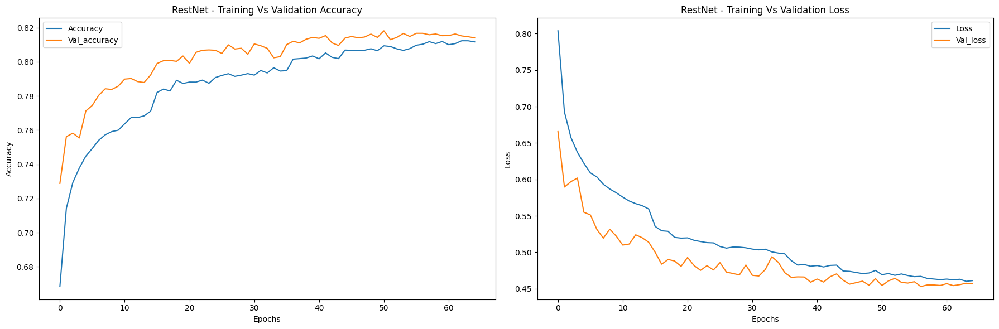

In [ ]:
plot_graphs(R_Net.history_head, "RestNet")                                 #  plotting the Accuracy and the loss graphs

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.8167 - loss: 0.4567

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 17s 52ms/step
Total inference time: 19.56s for 15000 samples
Mean time per sample: 1.30 ms

---------------------------------------------------------


Correct predictions: 12251 / 15000 --(81.67%) 
Number of correct predictions above 90% confidence  : 6965 --(56.85%) 
Number of correct predictions    80-90% confidence  : 1701 --(13.88%) 
Number of correct predictions    70-80% confidence  : 1282 --(10.46%) 
Number of correct predictions    50-70% confidence  : 1973 --(16.10%) 
Number of correct predictions less  50% confidence  : 330 --(2.69%) 

---------------------------------------------------------


Wrong predictions: 2749 / 15000 --(18.33%) 
Wrong above 90% confidence  : 300 --Band accuracy (95.87%) 
Wrong    80-90% confidence  : 327 --Band accuracy (83.88%) 


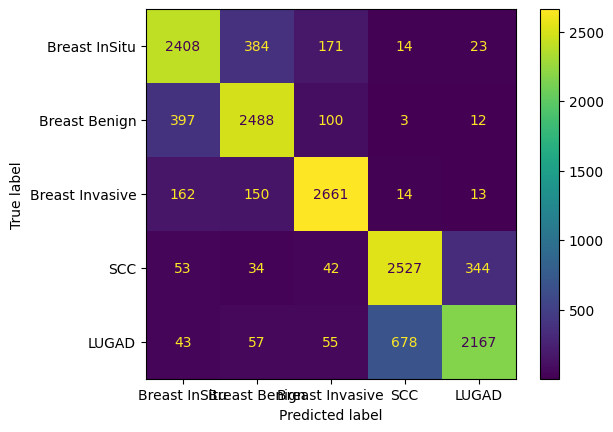

                 precision    recall  f1-score   support

  Breast InSitu       0.79      0.80      0.79      3000
  Breast Benign       0.80      0.83      0.81      3000
Breast Invasive       0.88      0.89      0.88      3000
            SCC       0.78      0.84      0.81      3000
          LUGAD       0.85      0.72      0.78      3000

       accuracy                           0.82     15000
      macro avg       0.82      0.82      0.82     15000
   weighted avg       0.82      0.82      0.82     15000


---------------------------------------------------------  


Macro_roc_auc = 0.97172085 


In [ ]:
load(R_Net, "resnet50v2_Head_training.keras")
R_Net.evaluate(Resnet_test_generator)

## RestNet50 Tuning Training and results


In [ ]:
R_Net.tuning (Resnet_train_generator, Resnet_val_generator, early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70 )

----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,142,293 (95.91 MB)

 Trainable params: 23,999,749 (91.55 MB)

 Non-trainable params: 90,880 (355.00 KB)

 Optimizer params: 1,051,664 (4.01 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 353s 268ms/step - accuracy: 0.8177 - loss: 0.4425 - val_accuracy: 0.8227 - val_loss: 0.4510 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 217ms/step - accuracy: 0.8395 - loss: 0.3905 - val_accuracy: 0.8451 - val_loss: 0.3883 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 216ms/step - accuracy: 0.8512 - loss: 0.3605 - val_accuracy: 0.8611 - val_loss: 0.3405 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 217ms/step - accuracy: 0.8615 - loss: 0.3388 - val_accuracy: 0.8715 - val_loss: 0.3155 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 217ms/step - accuracy: 0.8671 - loss: 0.3250 - val_accuracy: 0.8696 - val_loss: 0.3302 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 217ms/step - accuracy: 0.8724 - loss: 0.3090 - val_accuracy: 0.8746 - val_loss: 0.3014 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

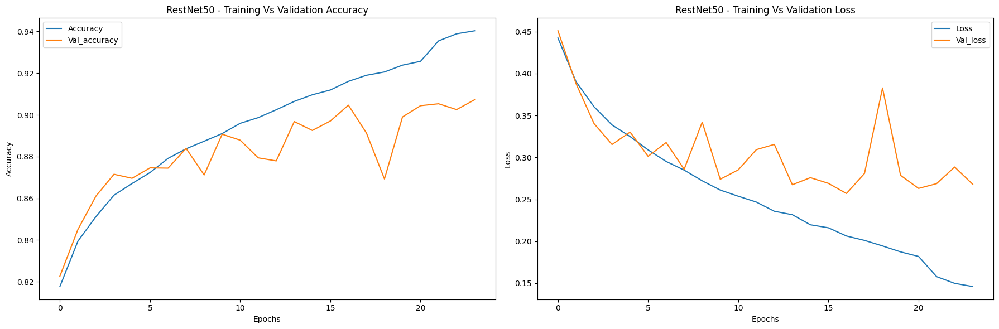

In [ ]:
plot_graphs(R_Net.history_tune, "RestNet50")                                 #  plotting the Accuracy and the loss graphs

##Training Graph for both Stage 1 and Stage 2

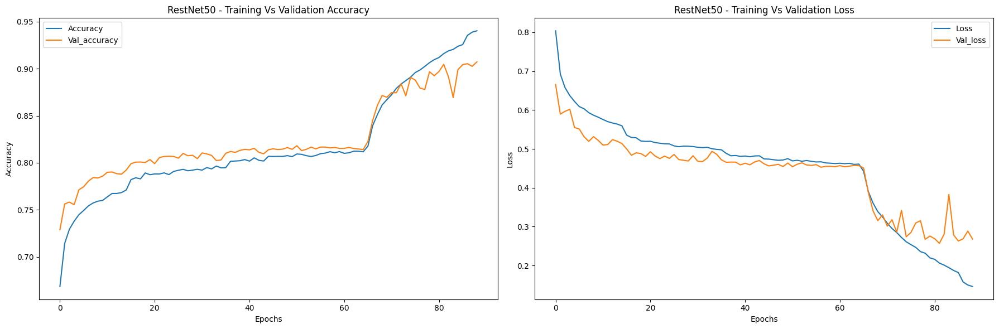

In [ ]:
plot_graphs(R_Net.history_all, "RestNet50")                                 #  plotting the Accuracy and the loss graphs

## RestNet50 Evaluation

In [34]:
load(R_Net, "resnet50v2_Tuning.keras")


 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.9094 - loss: 0.2364

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step
Total inference time: 19.68s for 15000 samples
Mean time per sample: 1.31 ms

---------------------------------------------------------


Correct predictions: 13641 / 15000 --(90.94%) 
Number of correct predictions above 90% confidence  : 11199 --(82.10%) 
Number of correct predictions    80-90% confidence  : 889 --(6.52%) 
Number of correct predictions    70-80% confidence  : 608 --(4.46%) 
Number of correct predictions    50-70% confidence  : 918 --(6.73%) 
Number of correct predictions less  50% confidence  : 27 --(0.20%) 

---------------------------------------------------------


Wrong predictions: 1359 / 15000 --(9.06%) 
Wrong above 90% confidence  : 285 --Band accuracy (97.52%) 
Wrong    80-90% confidence  : 230 --Band accuracy (79.45%) 
Wrong  

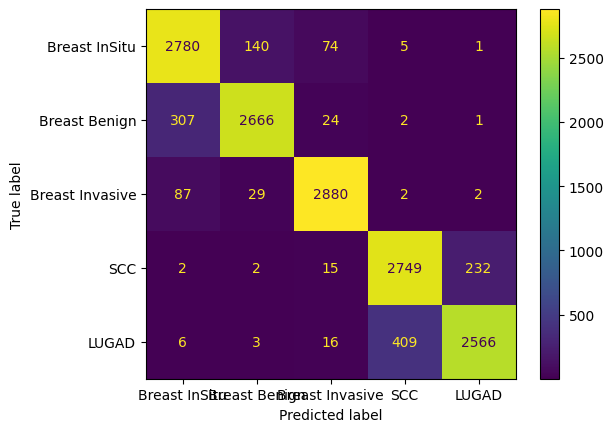

                 precision    recall  f1-score   support

  Breast InSitu       0.87      0.93      0.90      3000
  Breast Benign       0.94      0.89      0.91      3000
Breast Invasive       0.96      0.96      0.96      3000
            SCC       0.87      0.92      0.89      3000
          LUGAD       0.92      0.86      0.88      3000

       accuracy                           0.91     15000
      macro avg       0.91      0.91      0.91     15000
   weighted avg       0.91      0.91      0.91     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9921289166666668 


In [ ]:
load(R_Net, "resnet50v2_Tuning.keras")
R_Net.evaluate(Resnet_test_generator)

## RestNet50 GradCam

In [44]:
# Selection of 2 Random Images per class for Testing and Confidence level

test_folder = Path("/content/test")
Num_per_class = 2
extensions = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]

# Fixed random seed
rng = random.Random(60)

raw_image_path = []

for class_folder in sorted(p for p in test_folder.iterdir() if p.is_dir()):
    class_files = sorted([
        path
        for path in class_folder.rglob("*")
        if path.suffix.lower() in extensions
    ])

    raw_image_path += rng.sample(class_files,Num_per_class)

class_name = [image.parent.name for image in raw_image_path]

Num_samples = len(raw_image_path)

Predicted class: Breast Benign
Probability: 99.6862%
Time: 0.27 Sec
Correct Prediction


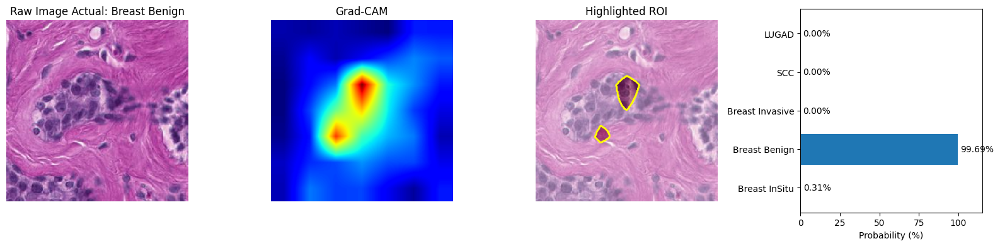

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 100.0000%
Time: 0.26 Sec
Correct Prediction


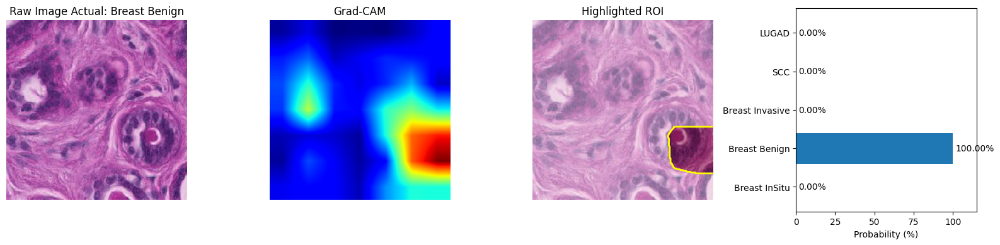

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 98.5468%
Time: 0.26 Sec
Correct Prediction


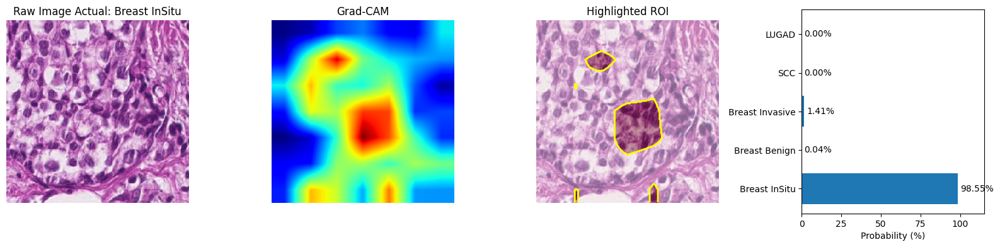

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9968%
Time: 0.26 Sec
Correct Prediction


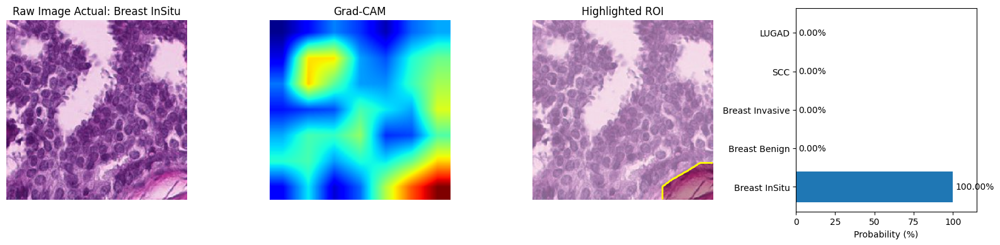

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.27 Sec
Correct Prediction


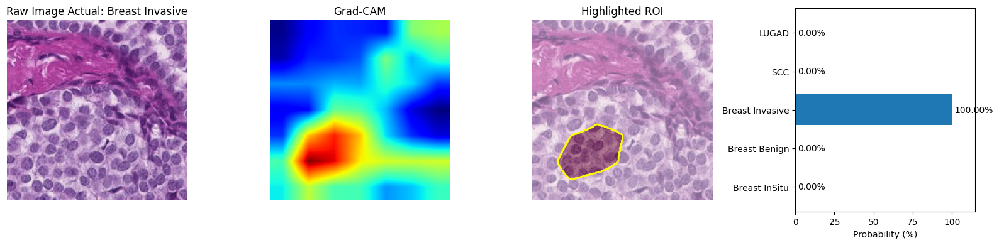

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.26 Sec
Correct Prediction


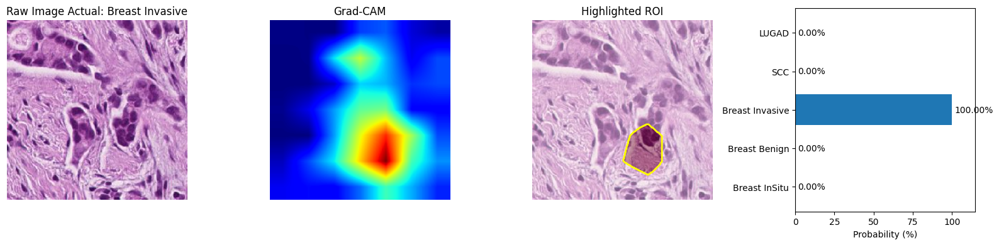

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 99.8272%
Time: 0.26 Sec
Correct Prediction


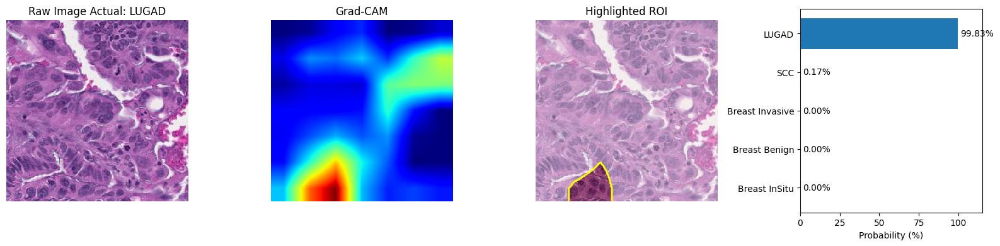

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.2496%
Time: 0.26 Sec
Wrong Prediction


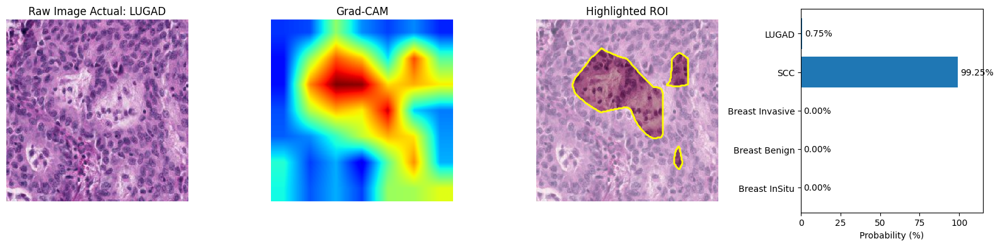

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.8846%
Time: 0.26 Sec
Correct Prediction


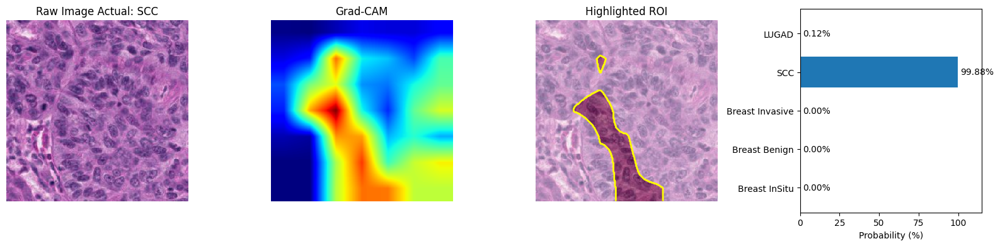

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 72.9497%
Time: 0.26 Sec
Correct Prediction


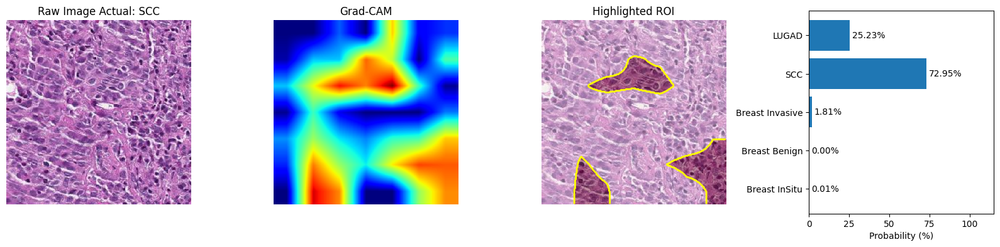

------------------------------------------------------------------------------------------------------------------------------------------------------


In [45]:
for i in range(Num_samples):
  R_Net.grad_cam(raw_image_path[i],class_name[i], threshold=0.7)
  print("-"*150)


Wronge Prediction

# Building Densenet Model


In [46]:
D_Net =  Build_model (backbone_name= "densenet169", dense_layer=256, dropout=0.5);

In [ ]:
#load (D_Net, "densenet169_Tuning.keras")

## DenseNet Head Training and results

In [ ]:

D_Net.head_training(Densenet_train_generator, Densenet_val_generator , early_stop_patient= 8, learning_rate = 0.001, N_Epochs = 70)



----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,070,405 (49.86 MB)

 Trainable params: 427,525 (1.63 MB)

 Non-trainable params: 12,642,880 (48.23 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 385s 304ms/step - accuracy: 0.6870 - loss: 0.7516 - val_accuracy: 0.7708 - val_loss: 0.5608 - learning_rate: 0.0010
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 259s 234ms/step - accuracy: 0.7366 - loss: 0.6339 - val_accuracy: 0.7817 - val_loss: 0.5231 - learning_rate: 0.0010
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 259s 234ms/step - accuracy: 0.7514 - loss: 0.6000 - val_accuracy: 0.7798 - val_loss: 0.5252 - learning_rate: 0.0010
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 259s 234ms/step - accuracy: 0.7558 - loss: 0.5816 - val_accuracy: 0.7861 - val_loss: 0.5119 - learning_rate: 0.0010
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 259s 234ms/step - accuracy: 0.7629 - loss: 0.5683 - val_accuracy: 0.7848 - val_loss: 0.5222 - learning_rate: 0.0010
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 259s 234ms/step - accuracy: 0.7695 - loss: 0.5548 - val_accuracy: 0.7931 - val_loss: 0.5029 - learning_rate: 0.0010
Epoch 7/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 260

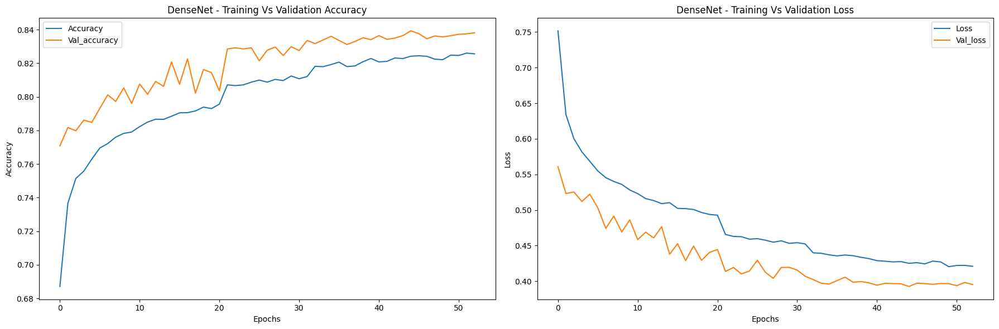

In [ ]:
plot_graphs(D_Net.history_head, "DenseNet")                                 #  plotting the Accuracy and the loss graphs

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 110ms/step - accuracy: 0.8381 - loss: 0.3852

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 50s 131ms/step
Total inference time: 54.94s for 15000 samples
Mean time per sample: 3.66 ms

---------------------------------------------------------


Correct predictions: 12572 / 15000 --(83.81%) 
Number of correct predictions above 90% confidence  : 7487 --(59.55%) 
Number of correct predictions    80-90% confidence  : 1614 --(12.84%) 
Number of correct predictions    70-80% confidence  : 1290 --(10.26%) 
Number of correct predictions    50-70% confidence  : 1990 --(15.83%) 
Number of correct predictions less  50% confidence  : 191 --(1.52%) 

---------------------------------------------------------


Wrong predictions: 2428 / 15000 --(16.19%) 
Wrong above 90% confidence  : 222 --Band accuracy (97.12%) 
Wrong    80-90% confidence  : 288 --Band accuracy (84.86%)

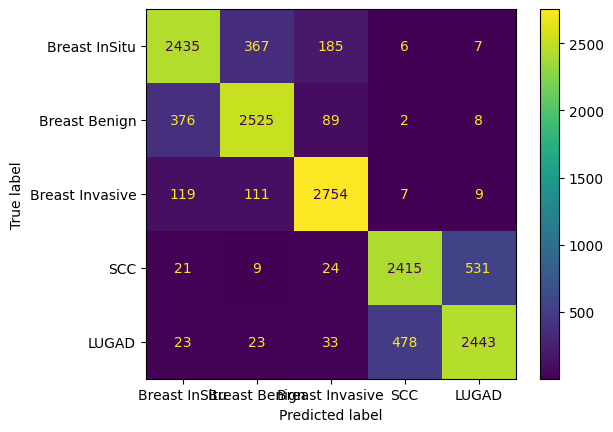

                 precision    recall  f1-score   support

  Breast InSitu       0.82      0.81      0.82      3000
  Breast Benign       0.83      0.84      0.84      3000
Breast Invasive       0.89      0.92      0.91      3000
            SCC       0.83      0.81      0.82      3000
          LUGAD       0.81      0.81      0.81      3000

       accuracy                           0.84     15000
      macro avg       0.84      0.84      0.84     15000
   weighted avg       0.84      0.84      0.84     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9789565194444444 


In [ ]:
load(D_Net, "densenet169_Head_training.keras")
D_Net.evaluate(Densenet_test_generator)

## DenseNet Tuning Training and results

In [ ]:
D_Net.tuning (Densenet_train_generator, Densenet_val_generator , early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70 )


----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,925,461 (53.12 MB)

 Trainable params: 12,753,605 (48.65 MB)

 Non-trainable params: 316,800 (1.21 MB)

 Optimizer params: 855,056 (3.26 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 680s 435ms/step - accuracy: 0.8203 - loss: 0.4347 - val_accuracy: 0.8545 - val_loss: 0.3548 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 261s 236ms/step - accuracy: 0.8444 - loss: 0.3822 - val_accuracy: 0.8643 - val_loss: 0.3232 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 261s 236ms/step - accuracy: 0.8546 - loss: 0.3528 - val_accuracy: 0.8639 - val_loss: 0.3365 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 261s 236ms/step - accuracy: 0.8657 - loss: 0.3259 - val_accuracy: 0.8670 - val_loss: 0.3211 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 261s 236ms/step - accuracy: 0.8708 - loss: 0.3160 - val_accuracy: 0.8847 - val_loss: 0.2812 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 261s 236ms/step - accuracy: 0.8783 - loss: 0.2968 - val_accuracy: 0.8753 - val_loss: 0.3116 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

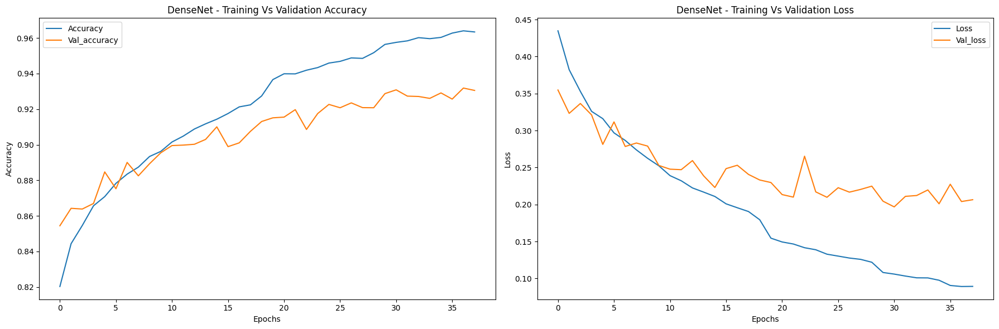

In [ ]:
plot_graphs(D_Net.history_tune, "DenseNet")                                 #  plotting the Accuracy and the loss graphs

## DenseNet Graph for Stage 1 and Stage 2



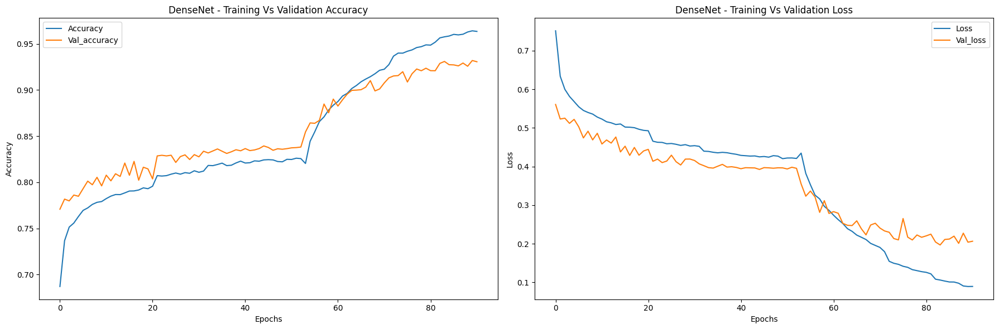

In [ ]:
plot_graphs(D_Net.history_all, "DenseNet")                                 #  plotting the Accuracy and the loss graphs


## DenseNet Evaluation

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 50s 114ms/step - accuracy: 0.9289 - loss: 0.2043

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 53s 140ms/step
Total inference time: 57.82s for 15000 samples
Mean time per sample: 3.85 ms

---------------------------------------------------------


Correct predictions: 13934 / 15000 --(92.89%) 
Number of correct predictions above 90% confidence  : 12660 --(90.86%) 
Number of correct predictions    80-90% confidence  : 511 --(3.67%) 
Number of correct predictions    70-80% confidence  : 329 --(2.36%) 
Number of correct predictions    50-70% confidence  : 428 --(3.07%) 
Number of correct predictions less  50% confidence  : 6 --(0.04%) 

---------------------------------------------------------


Wrong predictions: 1066 / 15000 --(7.11%) 
Wrong above 90% confidence  : 357 --Band accuracy (97.26%) 
Wrong    80-90% confidence  : 177 --Band accuracy (74.27%) 
Wrong 

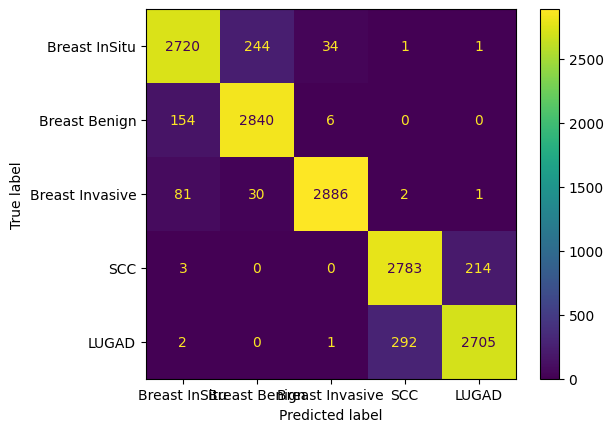

                 precision    recall  f1-score   support

  Breast InSitu       0.92      0.91      0.91      3000
  Breast Benign       0.91      0.95      0.93      3000
Breast Invasive       0.99      0.96      0.97      3000
            SCC       0.90      0.93      0.92      3000
          LUGAD       0.93      0.90      0.91      3000

       accuracy                           0.93     15000
      macro avg       0.93      0.93      0.93     15000
   weighted avg       0.93      0.93      0.93     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9951373111111111 


In [ ]:
load(D_Net, "densenet169_Tuning.keras")
D_Net.evaluate(Densenet_test_generator)

## DenseNet GradCam

In [47]:
load(D_Net, "densenet169_Tuning.keras")

Predicted class: Breast Benign
Probability: 99.9995%
Time: 0.76 Sec
Correct Prediction


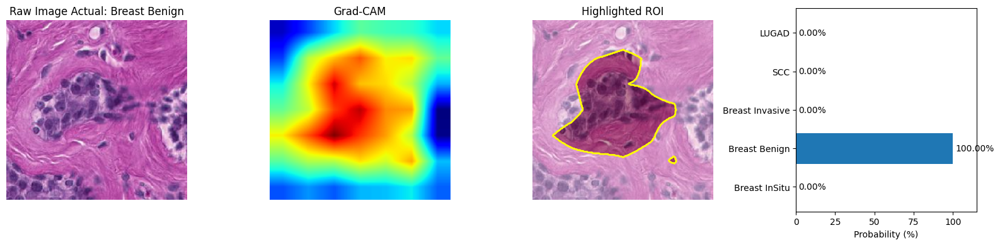

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 100.0000%
Time: 0.74 Sec
Correct Prediction


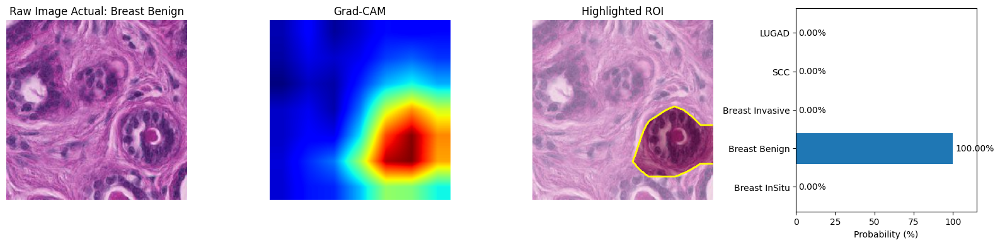

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9466%
Time: 0.74 Sec
Correct Prediction


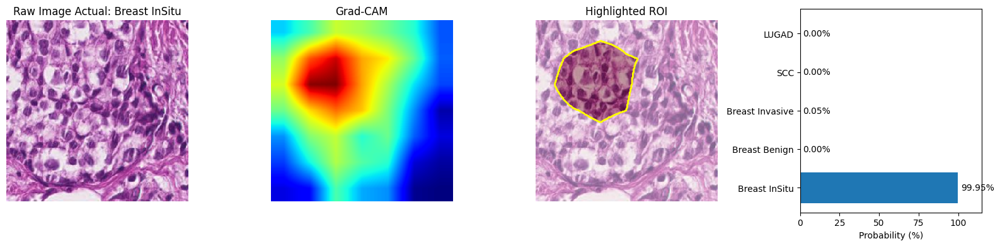

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9918%
Time: 0.74 Sec
Correct Prediction


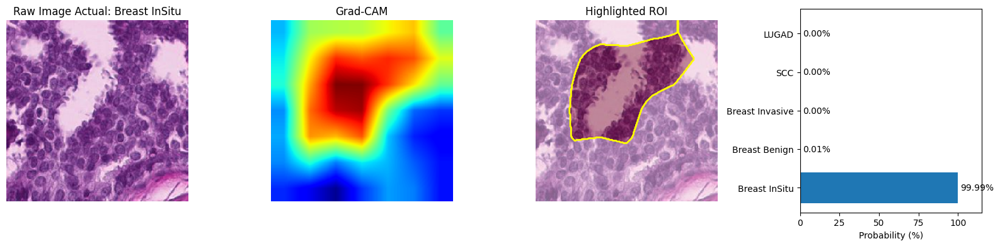

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.74 Sec
Correct Prediction


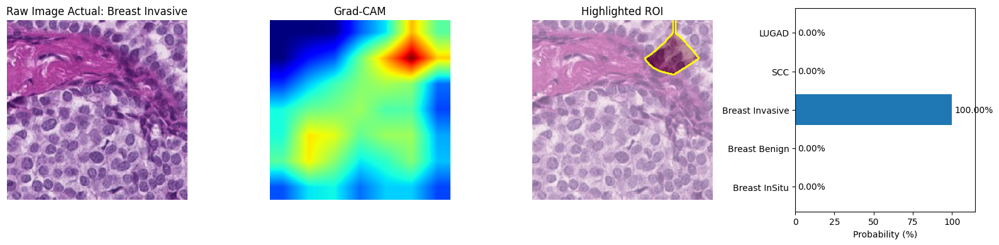

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.9999%
Time: 0.74 Sec
Correct Prediction


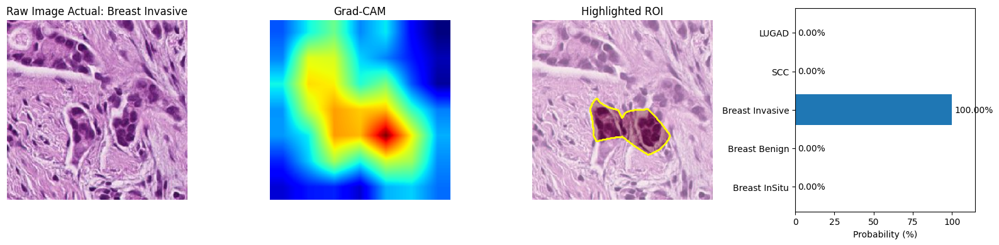

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 99.9995%
Time: 0.75 Sec
Correct Prediction


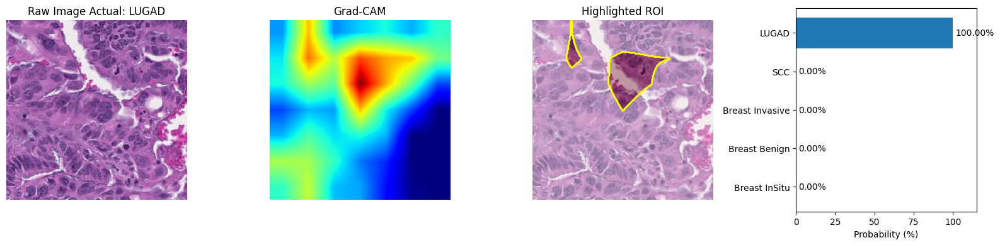

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 60.0523%
Time: 0.74 Sec
Correct Prediction


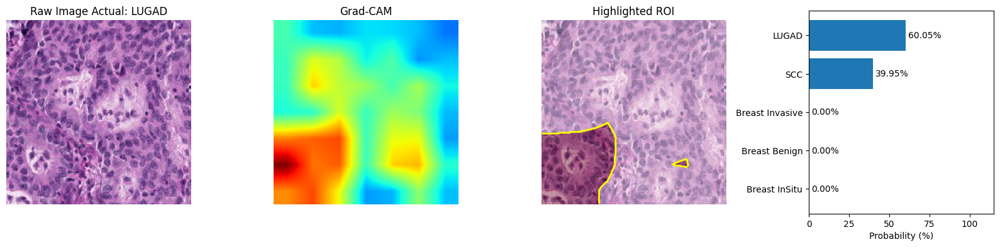

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.9999%
Time: 0.74 Sec
Correct Prediction


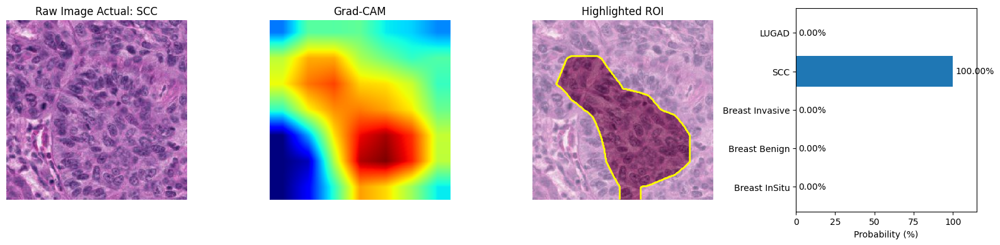

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 97.2897%
Time: 0.75 Sec
Wrong Prediction


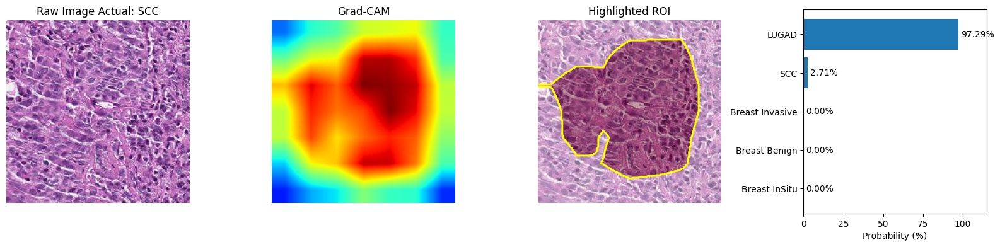

------------------------------------------------------------------------------------------------------------------------------------------------------


In [48]:
for i in range(Num_samples):
  D_Net.grad_cam(raw_image_path[i],class_name[i], threshold=0.7)
  print("-"*150)

# Failure Cases


ResNet50V2 | Actual: Breast Benign | BRACS_1810_UDH_36_y00384_x00256.jpg
Predicted class: Breast InSitu
Probability: 83.7624%
Time: 0.26 Sec
Wrong Prediction


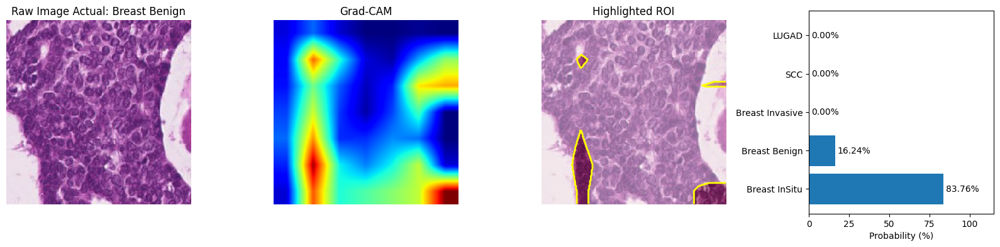


DenseNet169 | Actual: Breast Benign | BRACS_743_PB_27_y00384_x01152.jpg
Predicted class: Breast InSitu
Probability: 83.8926%
Time: 0.74 Sec
Wrong Prediction


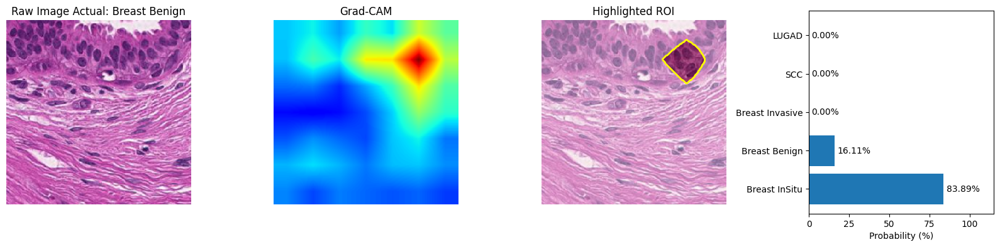


ResNet50V2 | Actual: Breast InSitu | BRACS_1877_ADH_3_y00256_x00256.jpg
Predicted class: Breast Benign
Probability: 74.9531%
Time: 0.26 Sec
Wrong Prediction


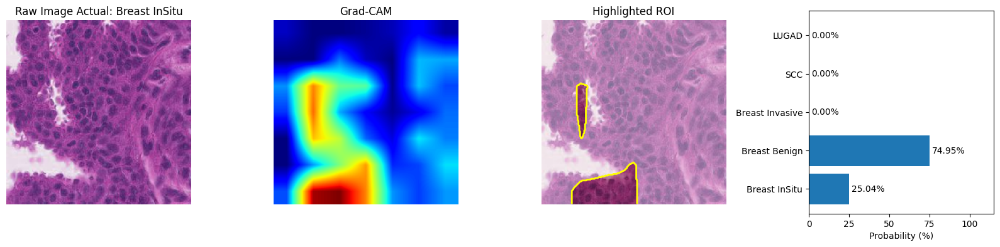


DenseNet169 | Actual: Breast InSitu | BRACS_1494_ADH_8_y00512_x00256.jpg
Predicted class: Breast Benign
Probability: 89.3361%
Time: 0.73 Sec
Wrong Prediction


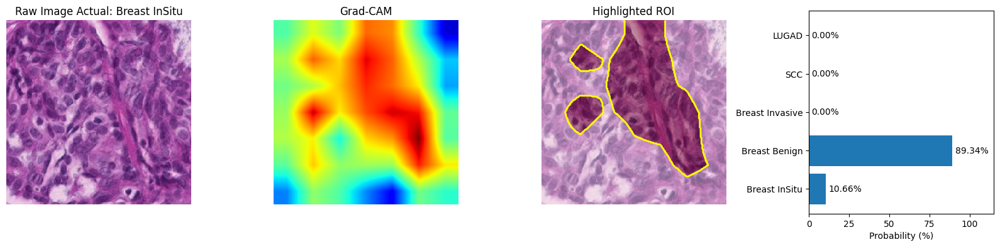


ResNet50V2 | Actual: Breast Invasive | BRACS_1639_IC_7_y00128_x00512.jpg
Predicted class: Breast InSitu
Probability: 97.1270%
Time: 0.26 Sec
Wrong Prediction


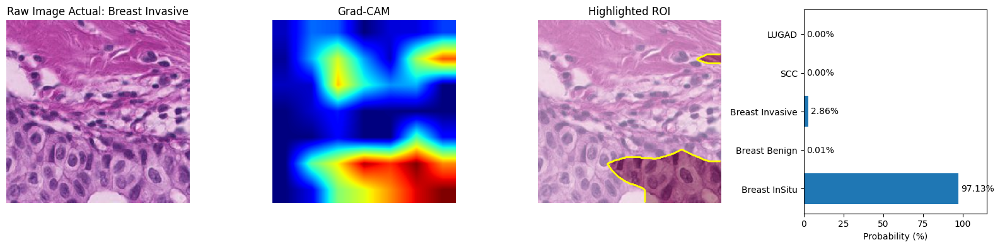


DenseNet169 | Actual: Breast Invasive | BRACS_1649_IC_2_y00640_x02176.jpg
Predicted class: Breast InSitu
Probability: 92.2204%
Time: 0.75 Sec
Wrong Prediction


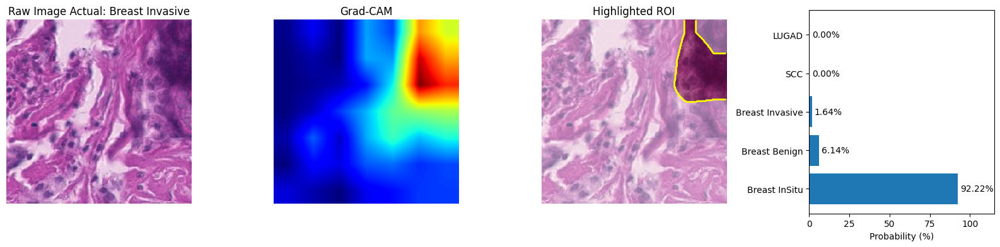


ResNet50V2 | Actual: SCC | 3_1_710_31.jpg
Predicted class: LUGAD
Probability: 56.0437%
Time: 0.26 Sec
Wrong Prediction


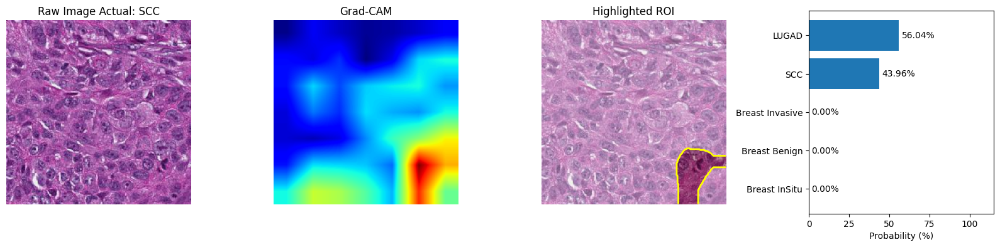


DenseNet169 | Actual: SCC | 1_8_714.jpg
Predicted class: LUGAD
Probability: 65.9225%
Time: 0.74 Sec
Wrong Prediction


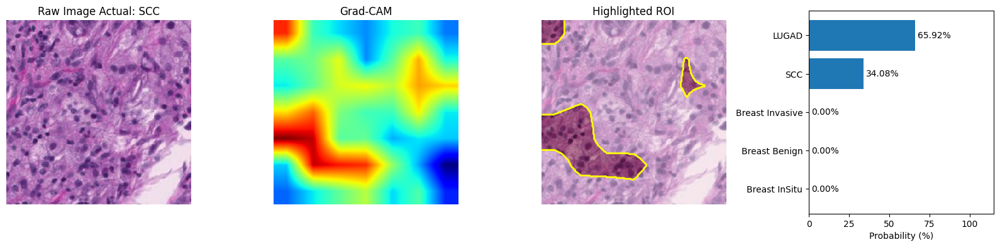


ResNet50V2 | Actual: LUGAD | 1_0_913_109.jpg
Predicted class: SCC
Probability: 65.1727%
Time: 0.26 Sec
Wrong Prediction


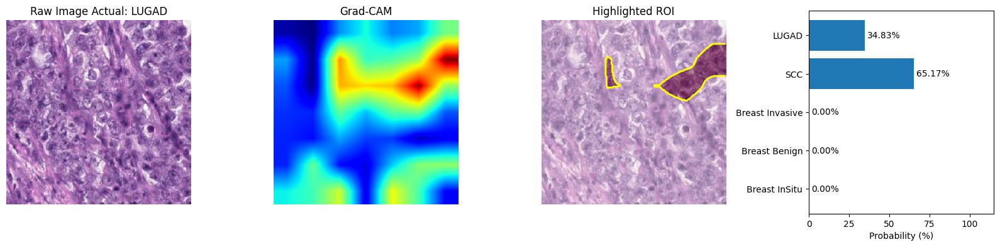


DenseNet169 | Actual: LUGAD | 0_8_833_5.jpg
Predicted class: SCC
Probability: 68.5956%
Time: 0.74 Sec
Wrong Prediction


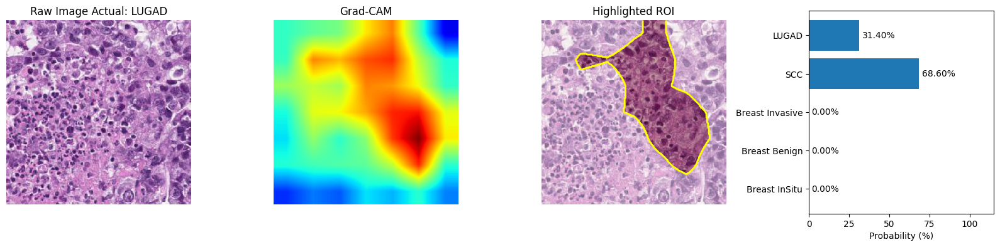

In [49]:
# Each row contains the true class, the ResNet failure, and the DenseNet failure.
cases = [
    ("Breast Benign",
     "BRACS_1810_UDH_36_y00384_x00256.jpg",
     "BRACS_743_PB_27_y00384_x01152.jpg"),

    ("Breast InSitu",
     "BRACS_1877_ADH_3_y00256_x00256.jpg",
     "BRACS_1494_ADH_8_y00512_x00256.jpg"),

    ("Breast Invasive",
     "BRACS_1639_IC_7_y00128_x00512.jpg",
     "BRACS_1649_IC_2_y00640_x02176.jpg"),

    ("SCC",
     "3_1_710_31.jpg",
     "1_8_714.jpg"),

    ("LUGAD",
     "1_0_913_109.jpg",
     "0_8_833_5.jpg"),
]

for true_class, resnet_file, densenet_file in cases:
    for name, model, filename in [
        ("ResNet50V2", R_Net, resnet_file),
        ("DenseNet169", D_Net, densenet_file),
    ]:
        patch = Path("/content/test") / true_class / filename
        if not patch.is_file():
            raise FileNotFoundError(f"Check that the original test set is unzipped: {patch}")

        print(f"\n{name} | Actual: {true_class} | {filename}")
        model.grad_cam(patch, true_class, threshold=0.7)

# Extra Experiments

# Trying Different learning rate @ 1e-4 for fine Tuning

## Fine Tune ResNet @ 1e-4

In [50]:
Lr_R_Net =  Build_model (backbone_name= "resnet50v2", dense_layer=256, dropout=0.5)

In [ ]:
load (Lr_R_Net, "resnet50v2_Head_training.keras")

In [ ]:
Lr_R_Net.tuning (Resnet_train_generator, Resnet_val_generator, early_stop_patient= 7, learning_rate = 0.0001, N_Epochs  = 70 )

----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,142,293 (95.91 MB)

 Trainable params: 23,999,749 (91.55 MB)

 Non-trainable params: 90,880 (355.00 KB)

 Optimizer params: 1,051,664 (4.01 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 307s 223ms/step - accuracy: 0.7441 - loss: 0.6418 - val_accuracy: 0.8199 - val_loss: 0.4324 - learning_rate: 1.0000e-04
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.8235 - loss: 0.4306 - val_accuracy: 0.8383 - val_loss: 0.3732 - learning_rate: 1.0000e-04
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.8423 - loss: 0.3822 - val_accuracy: 0.8295 - val_loss: 0.4206 - learning_rate: 1.0000e-04
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8528 - loss: 0.3610 - val_accuracy: 0.8155 - val_loss: 0.4503 - learning_rate: 1.0000e-04
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.8626 - loss: 0.3389 - val_accuracy: 0.8679 - val_loss: 0.3252 - learning_rate: 1.0000e-04
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.8685 - loss: 0.3252 - val_accuracy: 0.8401 - val_loss: 0.4342 - learning_rate: 1.0000e-04
Epoch 7/70
1094/1094 

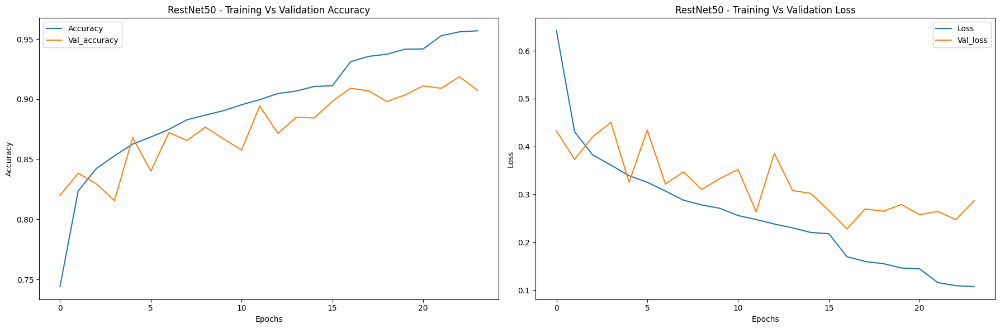

In [ ]:
plot_graphs(Lr_R_Net.history_tune, "RestNet50")                                 #  plotting the Accuracy and the loss graphs

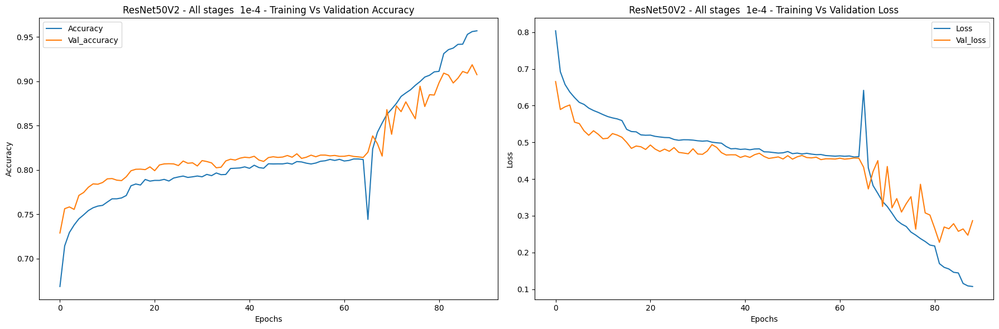

In [ ]:

h_head    = pd.read_csv(project_path / "resnet50v2_Head_training.csv",   index_col="epoch").to_dict("list")
h_full    = pd.read_csv(project_path / "LRresnet50v2_Tuning.csv",    index_col="epoch").to_dict("list")

Lr_R_Net.history_all = {k: list(h_head[k]) + list(h_full[k]) for k in h_full}

plot_graphs(Lr_R_Net.history_all, "ResNet50V2 - All stages  1e-4")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.9120 - loss: 0.2207

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step
Total inference time: 20.82s for 15000 samples
Mean time per sample: 1.39 ms

---------------------------------------------------------


Correct predictions: 13680 / 15000 --(91.20%) 
Number of correct predictions above 90% confidence  : 11583 --(84.67%) 
Number of correct predictions    80-90% confidence  : 861 --(6.29%) 
Number of correct predictions    70-80% confidence  : 536 --(3.92%) 
Number of correct predictions    50-70% confidence  : 682 --(4.99%) 
Number of correct predictions less  50% confidence  : 18 --(0.13%) 

---------------------------------------------------------


Wrong predictions: 1320 / 15000 --(8.80%) 
Wrong above 90% confidence  : 311 --Band accuracy (97.39%) 
Wrong    80-90% confidence  : 232 --Band accuracy (78.77%) 
Wrong   

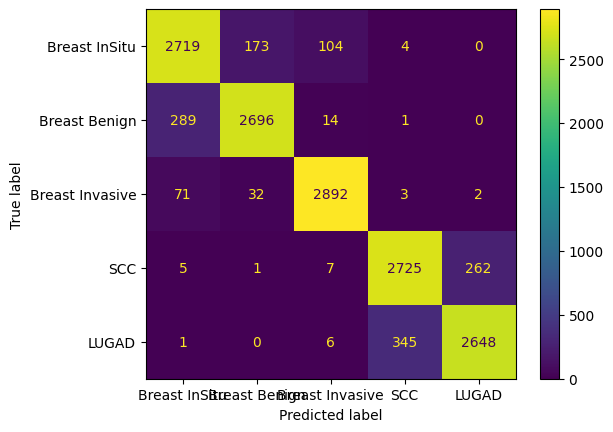

                 precision    recall  f1-score   support

  Breast InSitu       0.88      0.91      0.89      3000
  Breast Benign       0.93      0.90      0.91      3000
Breast Invasive       0.96      0.96      0.96      3000
            SCC       0.89      0.91      0.90      3000
          LUGAD       0.91      0.88      0.90      3000

       accuracy                           0.91     15000
      macro avg       0.91      0.91      0.91     15000
   weighted avg       0.91      0.91      0.91     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9930139638888889 


In [ ]:
Lr_R_Net.evaluate(Resnet_test_generator)

In [51]:
load (Lr_R_Net, "LRresnet50v2_Tuning.keras")

Predicted class: Breast Benign
Probability: 99.9042%
Time: 0.26 Sec
Correct Prediction


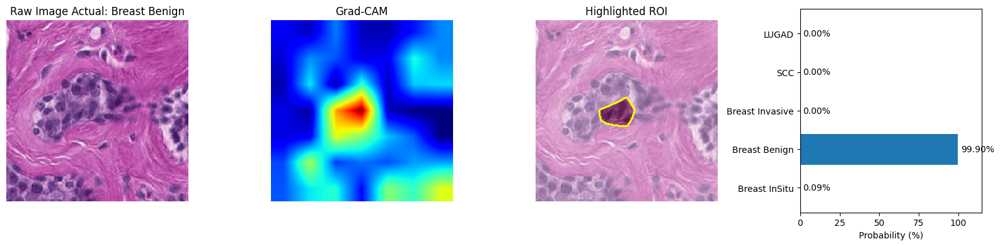

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 99.9993%
Time: 0.26 Sec
Correct Prediction


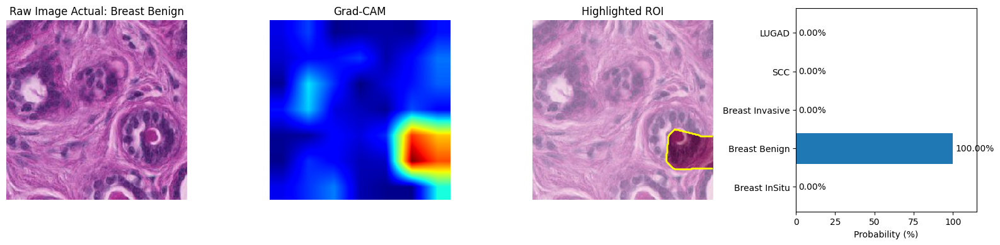

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.4435%
Time: 0.26 Sec
Correct Prediction


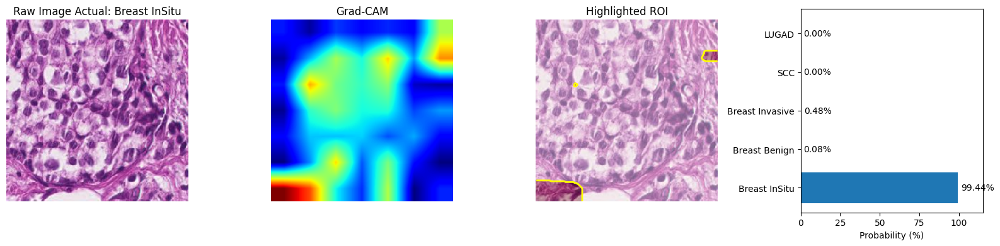

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9994%
Time: 0.27 Sec
Correct Prediction


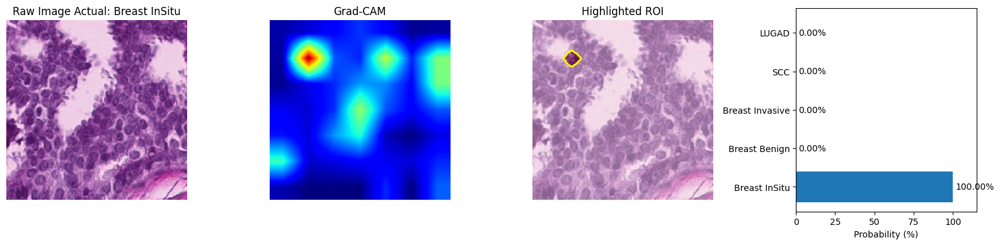

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.9921%
Time: 0.26 Sec
Correct Prediction


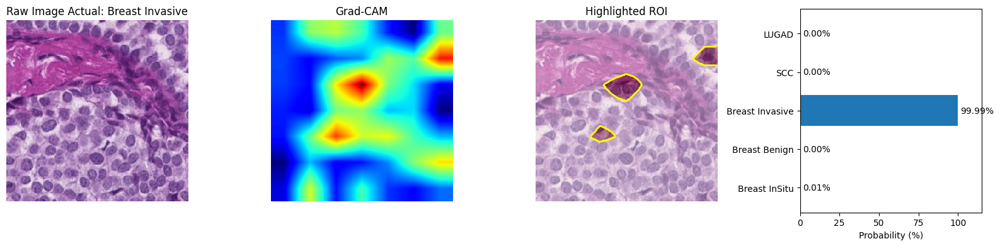

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.6419%
Time: 0.26 Sec
Correct Prediction


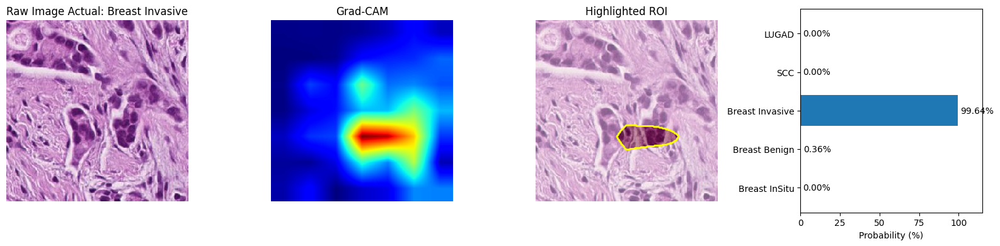

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 99.9992%
Time: 0.29 Sec
Correct Prediction


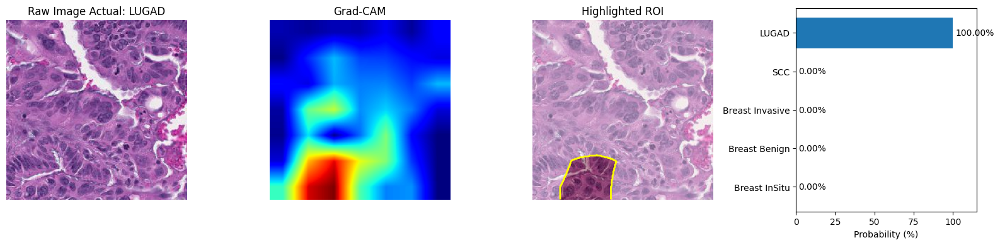

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 65.9942%
Time: 0.27 Sec
Wrong Prediction


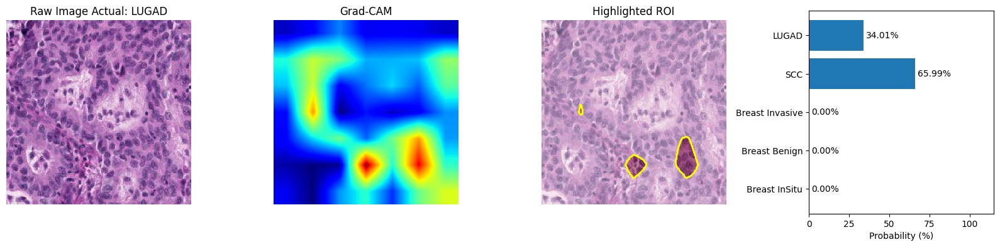

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 73.3867%
Time: 0.26 Sec
Correct Prediction


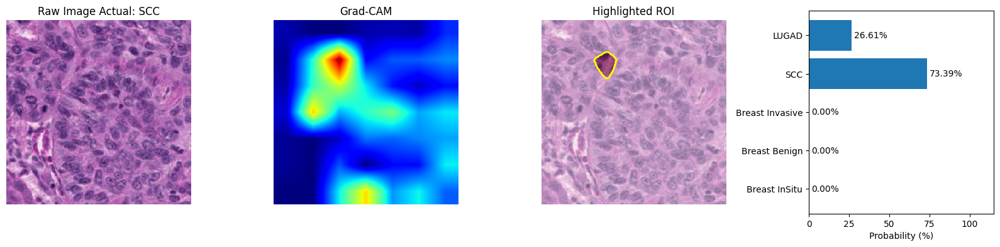

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 84.0128%
Time: 0.27 Sec
Wrong Prediction


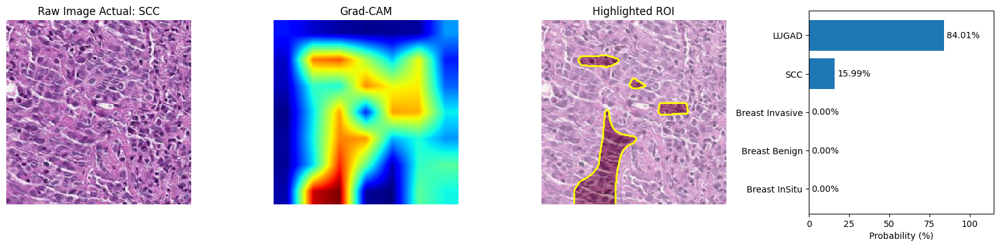

------------------------------------------------------------------------------------------------------------------------------------------------------


In [52]:
for i in range(Num_samples):
  Lr_R_Net.grad_cam(raw_image_path[i],class_name[i], threshold=0.7)
  print("-"*150)


## Fine Tune DesneNet @ 1e-4

In [53]:
Lr_D_Net =  Build_model (backbone_name= "densenet169", dense_layer=256, dropout=0.5);

In [ ]:
load (Lr_D_Net, "densenet169_Head_training.keras")

In [ ]:
Lr_D_Net.tuning (Densenet_train_generator, Densenet_val_generator , early_stop_patient= 7, learning_rate = 0.0001, N_Epochs  = 70 )


----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,925,461 (53.12 MB)

 Trainable params: 12,753,605 (48.65 MB)

 Non-trainable params: 316,800 (1.21 MB)

 Optimizer params: 855,056 (3.26 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 502s 321ms/step - accuracy: 0.6887 - loss: 0.7313 - val_accuracy: 0.7176 - val_loss: 0.6769 - learning_rate: 1.0000e-04
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8098 - loss: 0.4613 - val_accuracy: 0.8495 - val_loss: 0.3650 - learning_rate: 1.0000e-04
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8411 - loss: 0.3878 - val_accuracy: 0.8485 - val_loss: 0.3893 - learning_rate: 1.0000e-04
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8563 - loss: 0.3528 - val_accuracy: 0.8707 - val_loss: 0.3058 - learning_rate: 1.0000e-04
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8690 - loss: 0.3206 - val_accuracy: 0.8655 - val_loss: 0.3263 - learning_rate: 1.0000e-04
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8767 - loss: 0.3022 - val_accuracy: 0.8655 - val_loss: 0.3239 - learning_rate: 1.0000e-04
Epoch 7/70
1094/1094 

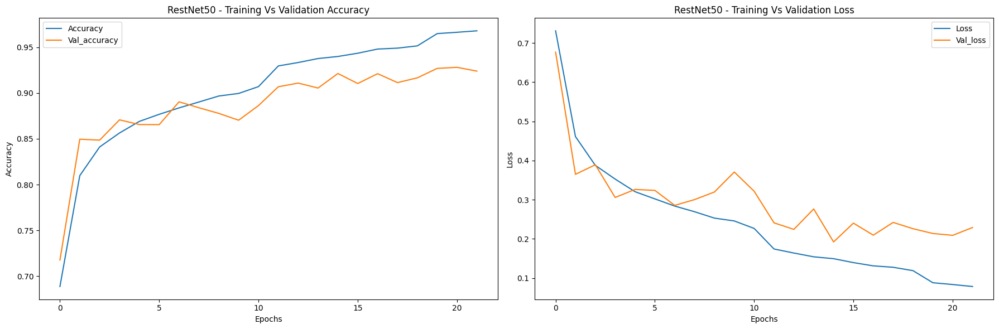

In [ ]:
plot_graphs(Lr_D_Net.history_tune, "RestNet50")

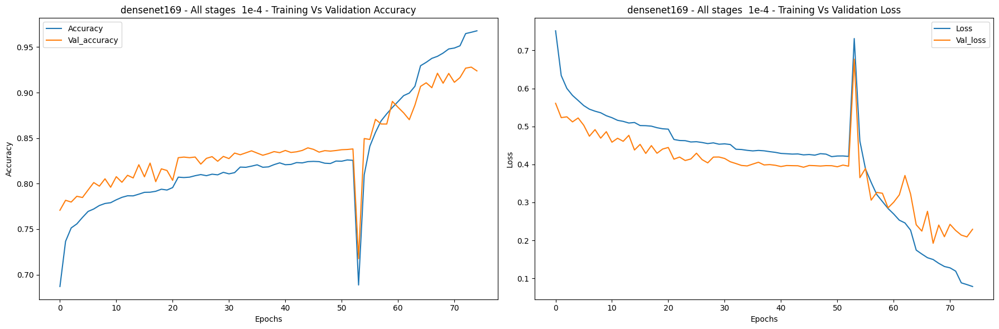

In [ ]:
h_head    = pd.read_csv(project_path / "densenet169_Head_training.csv",   index_col="epoch").to_dict("list")
h_full    = pd.read_csv(project_path / "LRdensenet169_Tuning.csv",    index_col="epoch").to_dict("list")

Lr_D_Net.history_all = {k: list(h_head[k]) + list(h_full[k]) for k in h_full}

plot_graphs(Lr_D_Net.history_all, "densenet169 - All stages  1e-4")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accuracy: 0.9255 - loss: 0.1850

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 53s 133ms/step
Total inference time: 57.36s for 15000 samples
Mean time per sample: 3.82 ms

---------------------------------------------------------


Correct predictions: 13883 / 15000 --(92.55%) 
Number of correct predictions above 90% confidence  : 11464 --(82.58%) 
Number of correct predictions    80-90% confidence  : 1038 --(7.48%) 
Number of correct predictions    70-80% confidence  : 596 --(4.29%) 
Number of correct predictions    50-70% confidence  : 776 --(5.59%) 
Number of correct predictions less  50% confidence  : 9 --(0.06%) 

---------------------------------------------------------


Wrong predictions: 1117 / 15000 --(7.45%) 
Wrong above 90% confidence  : 181 --Band accuracy (98.45%) 
Wrong    80-90% confidence  : 173 --Band accuracy (85.71%) 
Wrong 

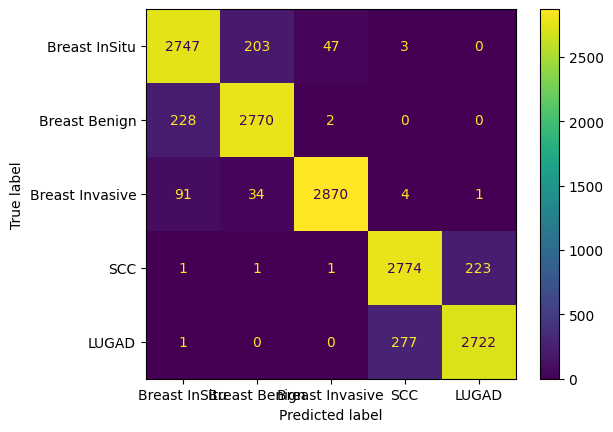

                 precision    recall  f1-score   support

  Breast InSitu       0.90      0.92      0.91      3000
  Breast Benign       0.92      0.92      0.92      3000
Breast Invasive       0.98      0.96      0.97      3000
            SCC       0.91      0.92      0.92      3000
          LUGAD       0.92      0.91      0.92      3000

       accuracy                           0.93     15000
      macro avg       0.93      0.93      0.93     15000
   weighted avg       0.93      0.93      0.93     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9947230027777778 


In [ ]:
Lr_D_Net.evaluate(Densenet_test_generator)

In [54]:
load (Lr_D_Net, "LRdensenet169_Tuning.keras")

Predicted class: Breast Benign
Probability: 99.9822%
Time: 0.73 Sec
Correct Prediction


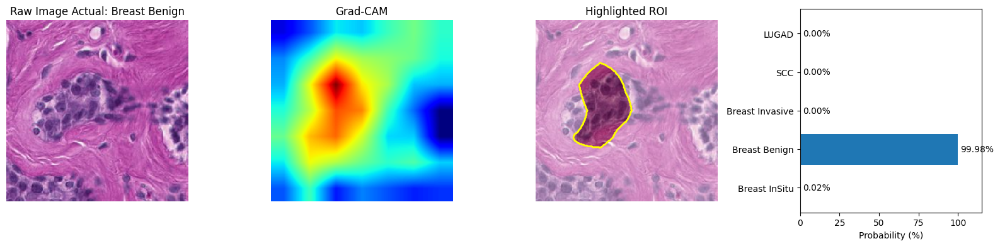

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 99.9997%
Time: 0.74 Sec
Correct Prediction


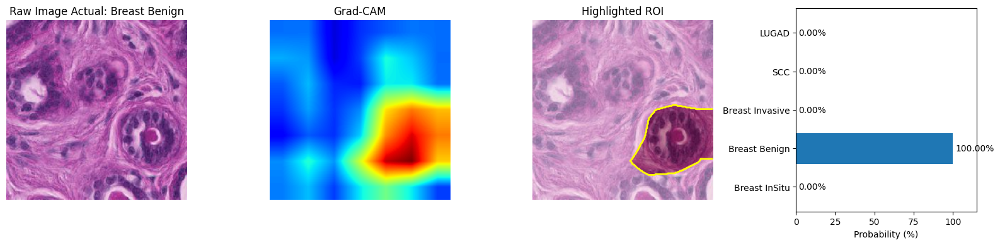

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9112%
Time: 0.75 Sec
Correct Prediction


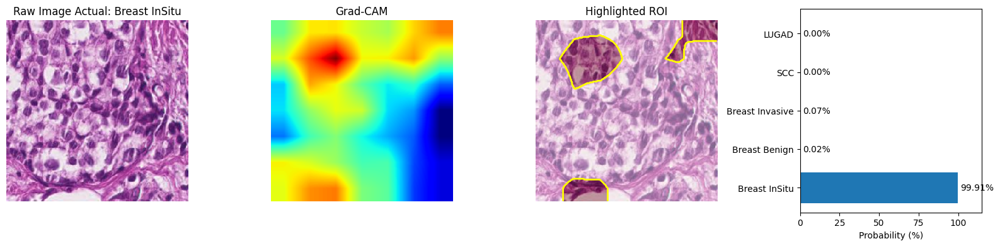

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 92.5623%
Time: 0.74 Sec
Correct Prediction


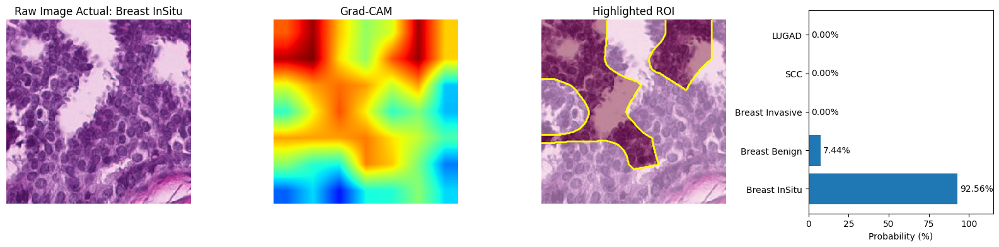

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.9985%
Time: 0.76 Sec
Correct Prediction


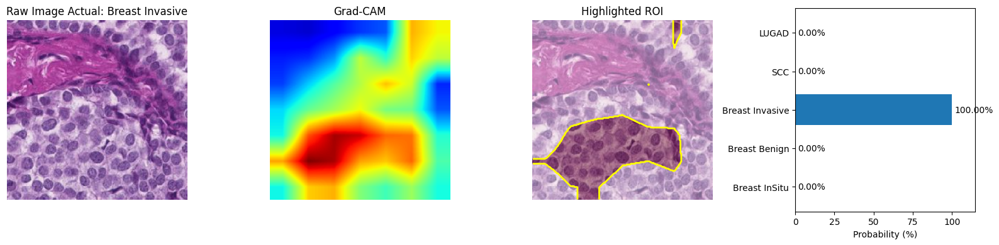

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.7388%
Time: 0.75 Sec
Correct Prediction


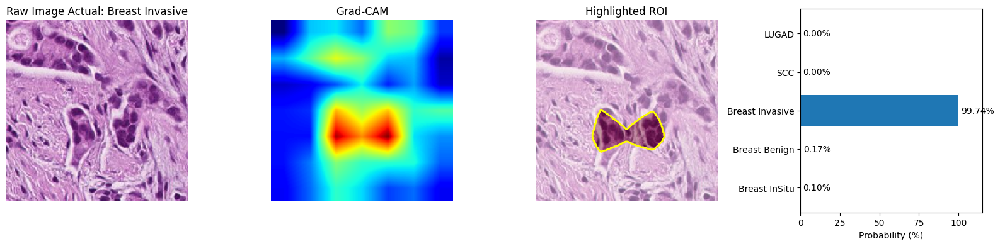

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 100.0000%
Time: 0.75 Sec
Correct Prediction


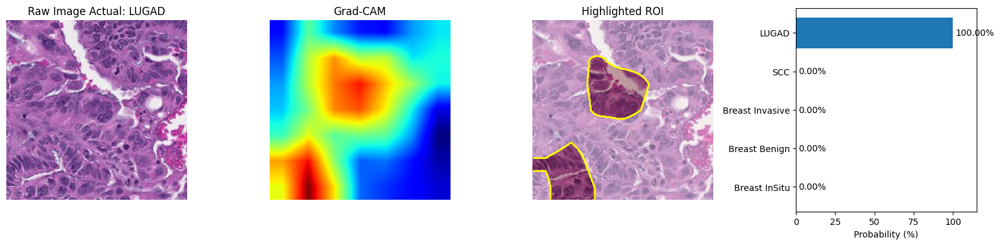

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 71.7959%
Time: 0.75 Sec
Correct Prediction


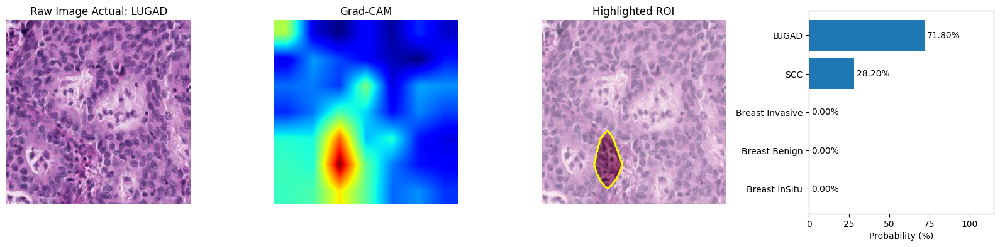

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 98.3956%
Time: 0.75 Sec
Correct Prediction


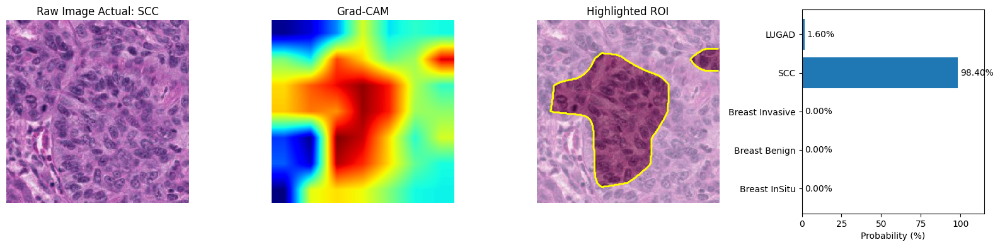

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 73.9726%
Time: 0.74 Sec
Correct Prediction


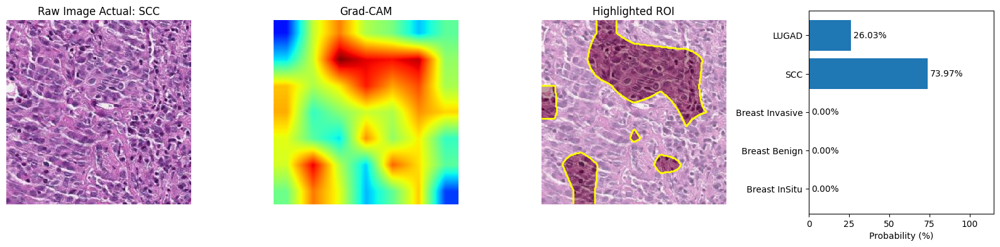

------------------------------------------------------------------------------------------------------------------------------------------------------


In [55]:
for i in range(Num_samples):
  Lr_D_Net.grad_cam(raw_image_path[i],class_name[i], threshold=0.7)
  print("-"*150)


ResNet50V2 | Actual: Breast Benign | BRACS_1810_UDH_36_y00384_x00256.jpg
Predicted class: Breast InSitu
Probability: 93.5565%
Time: 0.29 Sec
Wrong Prediction


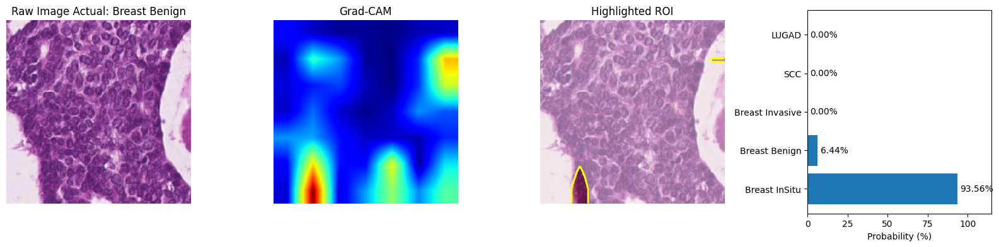


DenseNet169 | Actual: Breast Benign | BRACS_743_PB_27_y00384_x01152.jpg
Predicted class: Breast Benign
Probability: 95.0363%
Time: 0.76 Sec
Correct Prediction


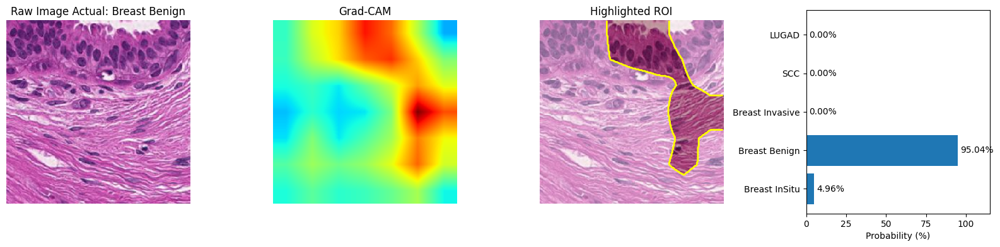


ResNet50V2 | Actual: Breast InSitu | BRACS_1877_ADH_3_y00256_x00256.jpg
Predicted class: Breast Benign
Probability: 66.4681%
Time: 0.27 Sec
Wrong Prediction


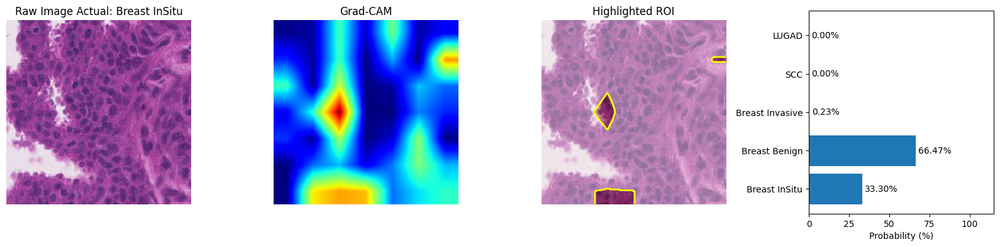


DenseNet169 | Actual: Breast InSitu | BRACS_1494_ADH_8_y00512_x00256.jpg
Predicted class: Breast InSitu
Probability: 60.3139%
Time: 0.75 Sec
Correct Prediction


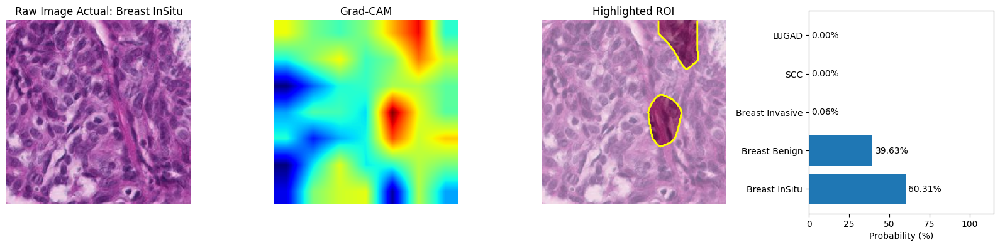


ResNet50V2 | Actual: Breast Invasive | BRACS_1639_IC_7_y00128_x00512.jpg
Predicted class: Breast InSitu
Probability: 87.6994%
Time: 0.27 Sec
Wrong Prediction


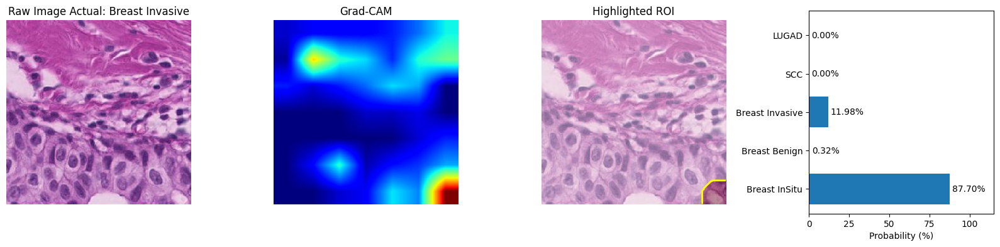


DenseNet169 | Actual: Breast Invasive | BRACS_1649_IC_2_y00640_x02176.jpg
Predicted class: Breast InSitu
Probability: 64.6530%
Time: 0.75 Sec
Wrong Prediction


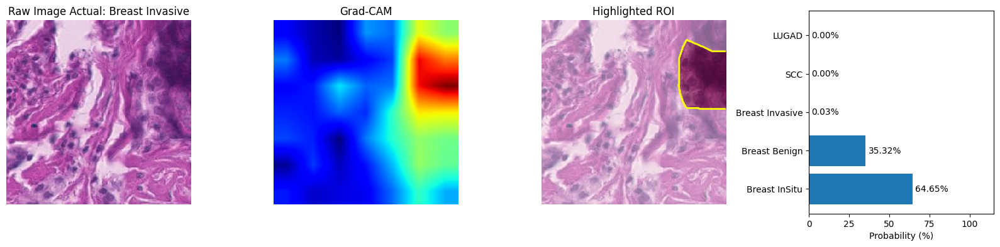


ResNet50V2 | Actual: SCC | 3_1_710_31.jpg
Predicted class: LUGAD
Probability: 73.3113%
Time: 0.28 Sec
Wrong Prediction


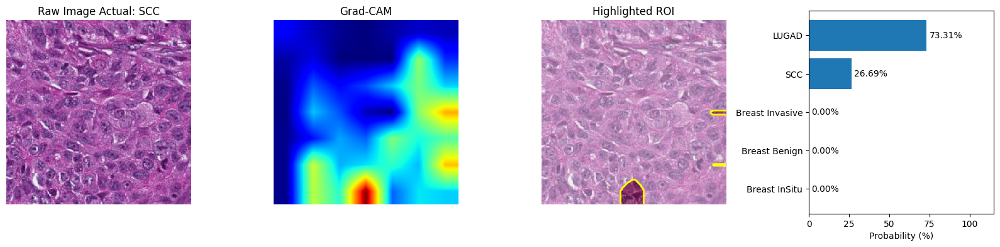


DenseNet169 | Actual: SCC | 1_8_714.jpg
Predicted class: LUGAD
Probability: 91.7189%
Time: 0.74 Sec
Wrong Prediction


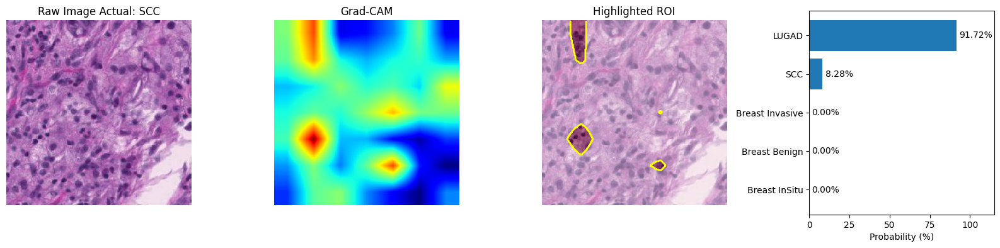


ResNet50V2 | Actual: LUGAD | 1_0_913_109.jpg
Predicted class: LUGAD
Probability: 62.3702%
Time: 0.26 Sec
Correct Prediction


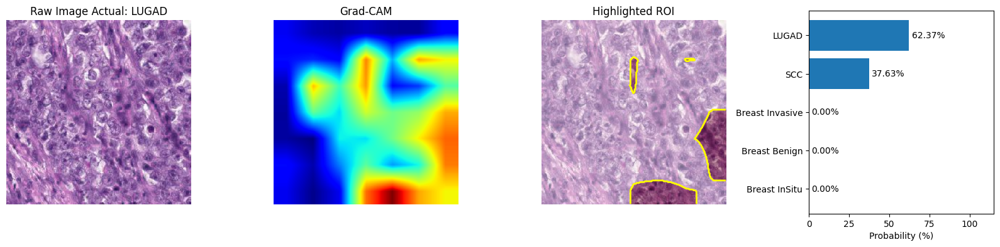


DenseNet169 | Actual: LUGAD | 0_8_833_5.jpg
Predicted class: LUGAD
Probability: 50.5229%
Time: 0.74 Sec
Correct Prediction


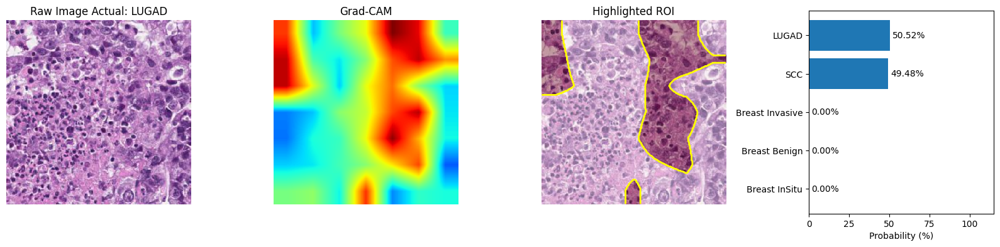

In [56]:
# Each row contains the true class, the ResNet failure, and the DenseNet failure.
cases = [
    ("Breast Benign",
     "BRACS_1810_UDH_36_y00384_x00256.jpg",
     "BRACS_743_PB_27_y00384_x01152.jpg"),

    ("Breast InSitu",
     "BRACS_1877_ADH_3_y00256_x00256.jpg",
     "BRACS_1494_ADH_8_y00512_x00256.jpg"),

    ("Breast Invasive",
     "BRACS_1639_IC_7_y00128_x00512.jpg",
     "BRACS_1649_IC_2_y00640_x02176.jpg"),

    ("SCC",
     "3_1_710_31.jpg",
     "1_8_714.jpg"),

    ("LUGAD",
     "1_0_913_109.jpg",
     "0_8_833_5.jpg"),
]

for true_class, resnet_file, densenet_file in cases:
    for name, model, filename in [
        ("ResNet50V2", Lr_R_Net, resnet_file),
        ("DenseNet169", Lr_D_Net, densenet_file),
    ]:
        patch = Path("/content/test") / true_class / filename
        if not patch.is_file():
            raise FileNotFoundError(f"Check that the original test set is unzipped: {patch}")

        print(f"\n{name} | Actual: {true_class} | {filename}")
        model.grad_cam(patch, true_class, threshold=0.7)

#  Partial Unfreezing (Extra Experiment)

* Train the head and the last block (conv5) only.
* Same settings as stage 2. Only the number of trained layers changes.
* Start from the saved stage 1 model, and save with a new name.

### ResNet50V2 - Partial Unfreezing  @ 1e-5



* Unfreeze the last stage (conv5) only, then train and evaluate.

In [ ]:
# Partial unfreeze : train only the last stage (conv5) of ResNet50V2, with lower learning rate to not affect the backbone
PR_Net =  Build_model (backbone_name= "resnet50v2", dense_layer=256, dropout=0.5)
load (PR_Net, "resnet50v2_Head_training.keras")

file_dis = "resnet50v2_PartialUnfreeze"
print("----------- Training --------------")

base = PR_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers[0:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False
  elif layer.name.startswith("conv5_"):      # last stage only
    layer.trainable = True
  else:
    layer.trainable = False

PR_Net.model.summary()

# Call Training and get history
PR_Net.history_partial = PR_Net.training(Resnet_train_generator, Resnet_val_generator, file_dis , early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70)





94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,142,293 (95.91 MB)

 Trainable params: 15,476,229 (59.04 MB)

 Non-trainable params: 8,614,400 (32.86 MB)

 Optimizer params: 1,051,664 (4.01 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 249s 195ms/step - accuracy: 0.8156 - loss: 0.4520 - val_accuracy: 0.8361 - val_loss: 0.4053 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 190s 171ms/step - accuracy: 0.8302 - loss: 0.4149 - val_accuracy: 0.8368 - val_loss: 0.4085 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8396 - loss: 0.3937 - val_accuracy: 0.8428 - val_loss: 0.3924 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 185s 168ms/step - accuracy: 0.8441 - loss: 0.3813 - val_accuracy: 0.8416 - val_loss: 0.3979 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8501 - loss: 0.3649 - val_accuracy: 0.8534 - val_loss: 0.3682 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8535 - loss: 0.3572 - val_accuracy: 0.8528 - val_loss: 0.3656 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

In [ ]:
# Save History
PR_Net.save_history(PR_Net.history_partial, file_dis )   # Just Save history as CSV

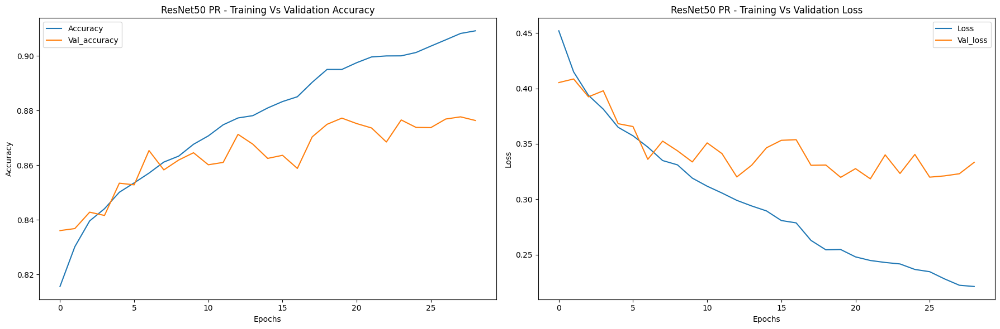

In [ ]:
plot_graphs(PR_Net.history_partial, "ResNet50 PR")                                 #  plotting the Accuracy and the loss graphs

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.8774 - loss: 0.3036

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step
Total inference time: 20.05s for 15000 samples
Mean time per sample: 1.34 ms

---------------------------------------------------------


Correct predictions: 13161 / 15000 --(87.74%) 
Number of correct predictions above 90% confidence  : 10237 --(77.78%) 
Number of correct predictions    80-90% confidence  : 1078 --(8.19%) 
Number of correct predictions    70-80% confidence  : 747 --(5.68%) 
Number of correct predictions    50-70% confidence  : 1038 --(7.89%) 
Number of correct predictions less  50% confidence  : 61 --(0.46%) 

---------------------------------------------------------


Wrong predictions: 1839 / 15000 --(12.26%) 
Wrong above 90% confidence  : 335 --Band accuracy (96.83%) 
Wrong    80-90% confidence  : 276 --Band accuracy (79.62%) 
Wrong

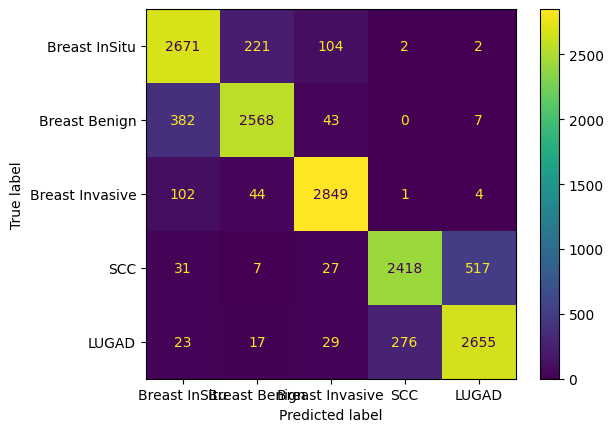

                 precision    recall  f1-score   support

  Breast InSitu       0.83      0.89      0.86      3000
  Breast Benign       0.90      0.86      0.88      3000
Breast Invasive       0.93      0.95      0.94      3000
            SCC       0.90      0.81      0.85      3000
          LUGAD       0.83      0.89      0.86      3000

       accuracy                           0.88     15000
      macro avg       0.88      0.88      0.88     15000
   weighted avg       0.88      0.88      0.88     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9880536333333334 


In [ ]:
# Evaluation
PR_Net.evaluate(Resnet_test_generator)

ResNet50V2
R1 – full unfreeze (from the partial-unfreeze checkpoint)

In [57]:
FR_Net =  Build_model (backbone_name= "resnet50v2", dense_layer=256, dropout=0.5)

In [ ]:

load (FR_Net, "resnet50v2_PartialUnfreeze.keras")

file_dis = "resnet50v2_FullUnfreeze"
print("----------- Training --------------")

base = FR_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers[0:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False
  else:
    layer.trainable = True

FR_Net.model.summary()


----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,043,093 (209.97 MB)

 Trainable params: 23,999,749 (91.55 MB)

 Non-trainable params: 90,880 (355.00 KB)

 Optimizer params: 30,952,464 (118.07 MB)

In [ ]:
FR_Net.history_full = FR_Net.training(Resnet_train_generator, Resnet_val_generator, file_dis , early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 239s 189ms/step - accuracy: 0.8857 - loss: 0.2796 - val_accuracy: 0.8567 - val_loss: 0.3988 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8923 - loss: 0.2657 - val_accuracy: 0.8807 - val_loss: 0.3170 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.8952 - loss: 0.2540 - val_accuracy: 0.8734 - val_loss: 0.3122 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8995 - loss: 0.2452 - val_accuracy: 0.8825 - val_loss: 0.3053 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.9033 - loss: 0.2361 - val_accuracy: 0.8827 - val_loss: 0.3076 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.9051 - loss: 0.2329 - val_accuracy: 0.8663 - val_loss: 0.3897 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

In [ ]:
FR_Net.save_history(FR_Net.history_full, file_dis)

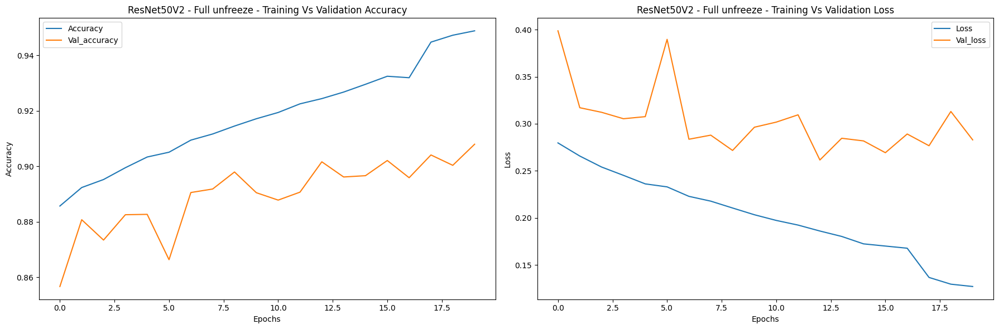

In [ ]:

h_head    = pd.read_csv(project_path / "resnet50v2_Head_training.csv",   index_col="epoch").to_dict("list")
h_partial = pd.read_csv(project_path / "resnet50v2_PartialUnfreeze.csv", index_col="epoch").to_dict("list")
h_full    = pd.read_csv(project_path / "resnet50v2_FullUnfreeze.csv",    index_col="epoch").to_dict("list")

plot_graphs(h_full,    "ResNet50V2 - Full unfreeze")
FR_Net.history_all = {k: list(h_head[k]) + list(h_partial[k]) + list(h_full[k]) for k in h_full}


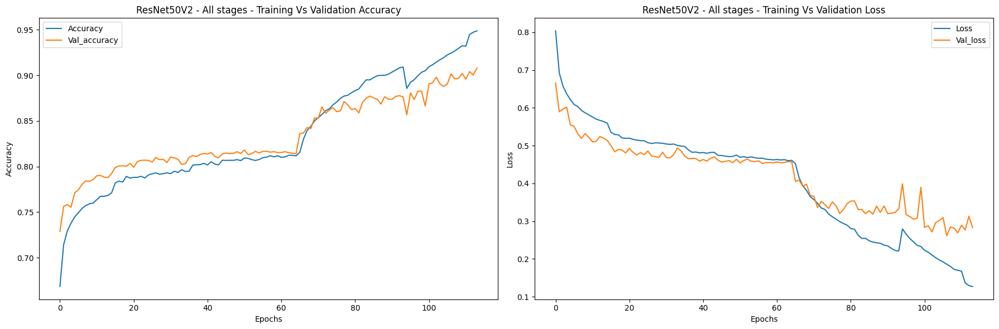

In [ ]:
plot_graphs(FR_Net.history_all, "ResNet50V2 - All stages")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.9076 - loss: 0.2442

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step
Total inference time: 20.63s for 15000 samples
Mean time per sample: 1.38 ms

---------------------------------------------------------


Correct predictions: 13614 / 15000 --(90.76%) 
Number of correct predictions above 90% confidence  : 11275 --(82.82%) 
Number of correct predictions    80-90% confidence  : 861 --(6.32%) 
Number of correct predictions    70-80% confidence  : 591 --(4.34%) 
Number of correct predictions    50-70% confidence  : 863 --(6.34%) 
Number of correct predictions less  50% confidence  : 24 --(0.18%) 

---------------------------------------------------------


Wrong predictions: 1386 / 15000 --(9.24%) 
Wrong above 90% confidence  : 299 --Band accuracy (97.42%) 
Wrong    80-90% confidence  : 198 --Band accuracy (81.30%) 
Wrong   

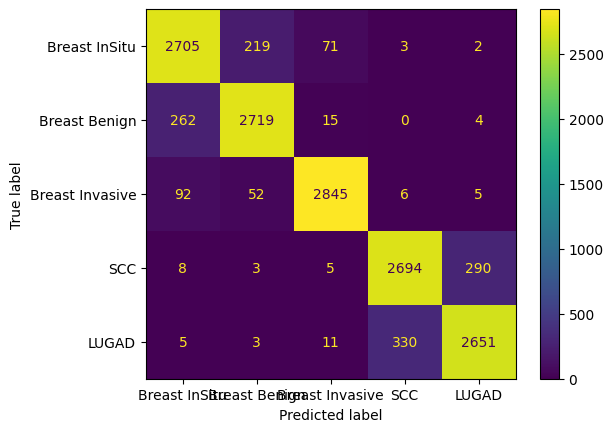

                 precision    recall  f1-score   support

  Breast InSitu       0.88      0.90      0.89      3000
  Breast Benign       0.91      0.91      0.91      3000
Breast Invasive       0.97      0.95      0.96      3000
            SCC       0.89      0.90      0.89      3000
          LUGAD       0.90      0.88      0.89      3000

       accuracy                           0.91     15000
      macro avg       0.91      0.91      0.91     15000
   weighted avg       0.91      0.91      0.91     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9919496194444445 


In [ ]:
# load(FR_Net, "resnet50v2_FullUnfreeze.keras")
FR_Net.evaluate(Resnet_test_generator)

In [58]:
load(FR_Net, "resnet50v2_FullUnfreeze.keras")

Predicted class: Breast Benign
Probability: 99.9894%
Time: 0.26 Sec
Correct Prediction


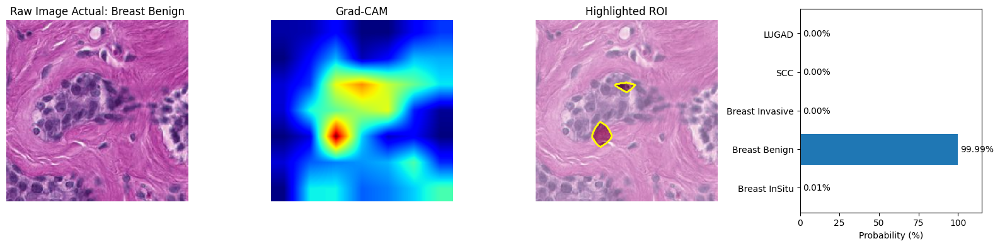

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 100.0000%
Time: 0.27 Sec
Correct Prediction


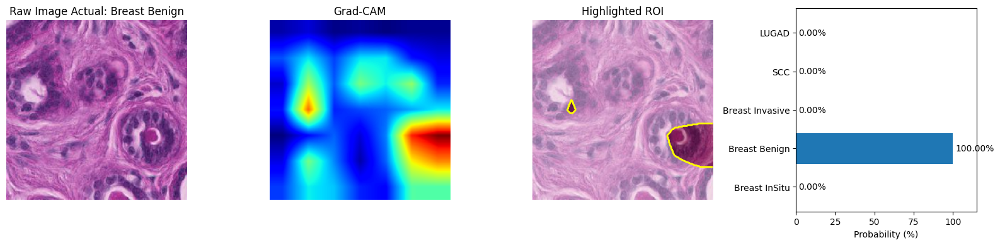

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 94.5305%
Time: 0.26 Sec
Correct Prediction


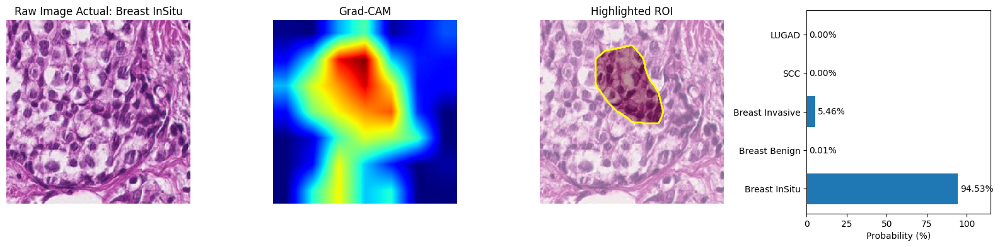

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 100.0000%
Time: 0.27 Sec
Correct Prediction


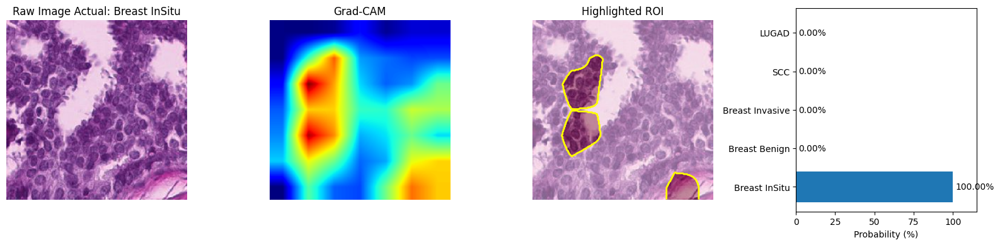

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.26 Sec
Correct Prediction


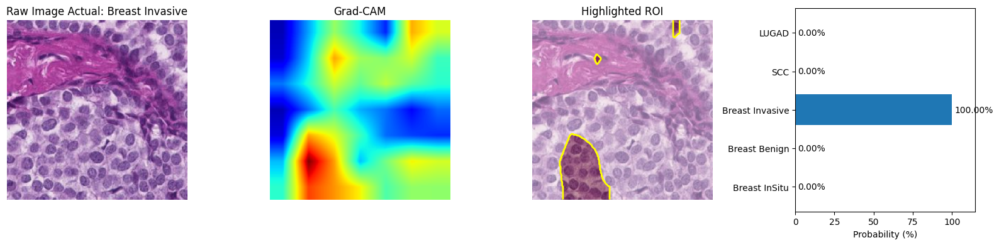

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.9728%
Time: 0.26 Sec
Correct Prediction


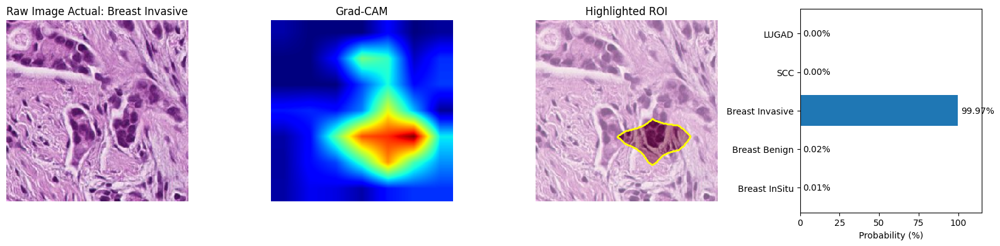

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 99.6271%
Time: 0.26 Sec
Correct Prediction


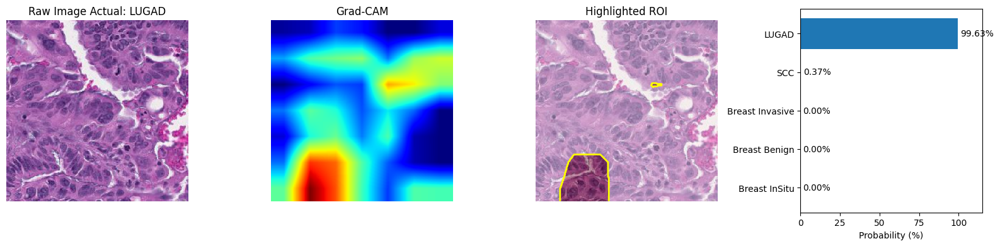

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 82.8761%
Time: 0.28 Sec
Correct Prediction


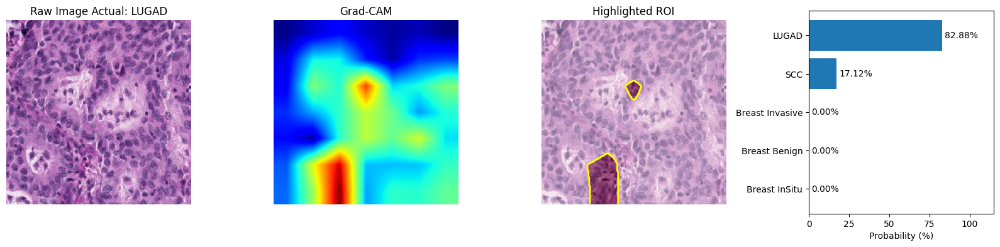

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.2955%
Time: 0.27 Sec
Correct Prediction


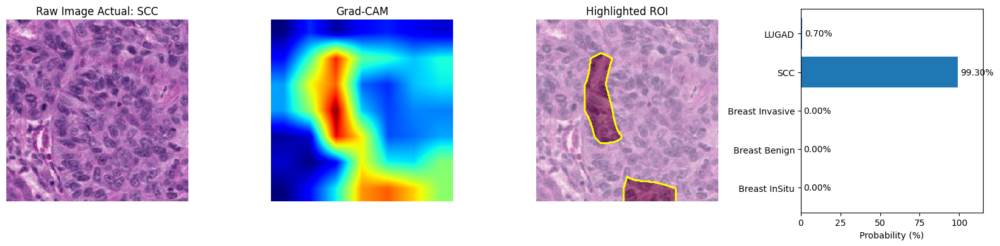

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 79.2145%
Time: 0.26 Sec
Wrong Prediction


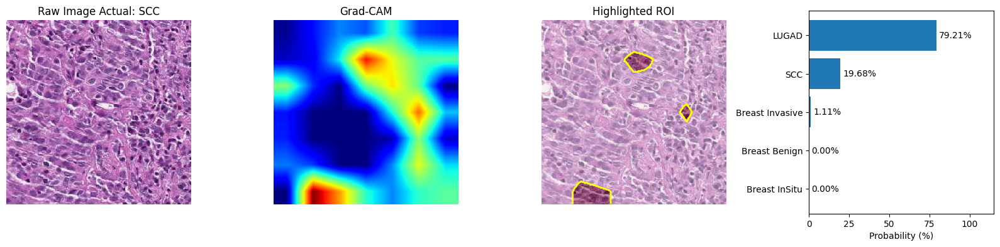

------------------------------------------------------------------------------------------------------------------------------------------------------


In [59]:
for i in range(Num_samples):
  FR_Net.grad_cam(raw_image_path[i],class_name[i], threshold=0.7)
  print("-"*150)

---------------------------

### DenseNet169 - Partial Unfreezing @ 1e-5
* Unfreeze the last dense block (conv5) only, then train and evaluate.

In [ ]:
# Partial unfreeze : train only the last dense block (conv5) of DenseNet169, with lower learning rate to not affect the backbone
PD_Net =  Build_model (backbone_name= "densenet169", dense_layer=256, dropout=0.5)
load (PD_Net, "densenet169_Head_training.keras")

file_dis = "densenet169_PartialUnfreeze"
print("----------- Training --------------")

base = PD_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers[0:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False
  elif layer.name.startswith("conv5_"):      # last dense block only
    layer.trainable = True
  else:
    layer.trainable = False

PD_Net.model.summary()

# Call Training and get history
PD_Net.history_partial = PD_Net.training(Densenet_train_generator, Densenet_val_generator, file_dis , early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70)



51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,925,461 (53.12 MB)

 Trainable params: 6,260,229 (23.88 MB)

 Non-trainable params: 6,810,176 (25.98 MB)

 Optimizer params: 855,056 (3.26 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 399s 276ms/step - accuracy: 0.8214 - loss: 0.4305 - val_accuracy: 0.8415 - val_loss: 0.3793 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 203s 184ms/step - accuracy: 0.8325 - loss: 0.4078 - val_accuracy: 0.8421 - val_loss: 0.3811 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 204s 184ms/step - accuracy: 0.8350 - loss: 0.3977 - val_accuracy: 0.8494 - val_loss: 0.3715 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 203s 184ms/step - accuracy: 0.8405 - loss: 0.3860 - val_accuracy: 0.8465 - val_loss: 0.3816 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 203s 184ms/step - accuracy: 0.8457 - loss: 0.3751 - val_accuracy: 0.8384 - val_loss: 0.4154 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 203s 184ms/step - accuracy: 0.8474 - loss: 0.3699 - val_accuracy: 0.8523 - val_loss: 0.3697 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

In [ ]:
# Save History
PD_Net.save_history(PD_Net.history_partial, file_dis )   # Just Save history as CSV

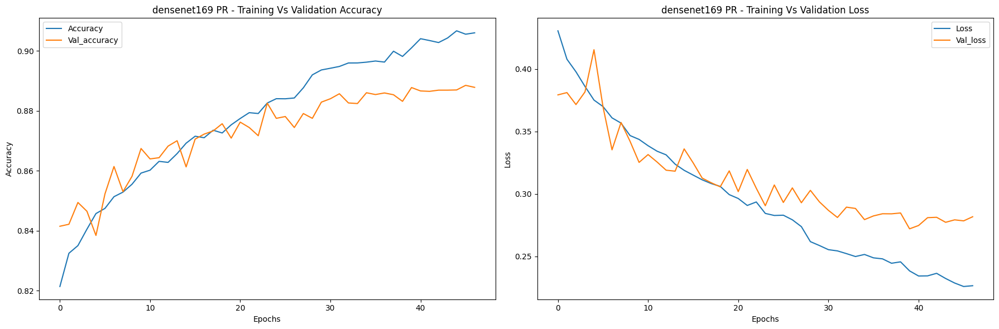

In [ ]:
plot_graphs(PD_Net.history_partial, "densenet169 PR")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.8911 - loss: 0.2651

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 131ms/step
Total inference time: 55.41s for 15000 samples
Mean time per sample: 3.69 ms

---------------------------------------------------------


Correct predictions: 13366 / 15000 --(89.11%) 
Number of correct predictions above 90% confidence  : 10155 --(75.98%) 
Number of correct predictions    80-90% confidence  : 1164 --(8.71%) 
Number of correct predictions    70-80% confidence  : 816 --(6.11%) 
Number of correct predictions    50-70% confidence  : 1188 --(8.89%) 
Number of correct predictions less  50% confidence  : 43 --(0.32%) 

---------------------------------------------------------


Wrong predictions: 1634 / 15000 --(10.89%) 
Wrong above 90% confidence  : 260 --Band accuracy (97.50%) 
Wrong    80-90% confidence  : 244 --Band accuracy (82.67%) 
Wro

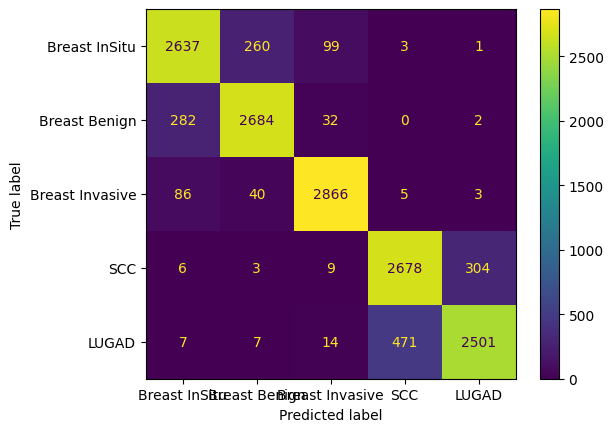

                 precision    recall  f1-score   support

  Breast InSitu       0.87      0.88      0.88      3000
  Breast Benign       0.90      0.89      0.90      3000
Breast Invasive       0.95      0.96      0.95      3000
            SCC       0.85      0.89      0.87      3000
          LUGAD       0.89      0.83      0.86      3000

       accuracy                           0.89     15000
      macro avg       0.89      0.89      0.89     15000
   weighted avg       0.89      0.89      0.89     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9895406555555557 


In [ ]:
# Evaluation
PD_Net.evaluate(Densenet_test_generator)

In [60]:
FD_Net = Build_model(backbone_name="densenet169", dense_layer=256, dropout=0.5)

In [ ]:
load(FD_Net, "densenet169_PartialUnfreeze.keras")

file_dis = "densenet169_FullUnfreeze"
print("----------- Training --------------")

base = FD_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers:
  layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

FD_Net.model.summary()

----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,590,869 (97.62 MB)

 Trainable params: 12,753,605 (48.65 MB)

 Non-trainable params: 316,800 (1.21 MB)

 Optimizer params: 12,520,464 (47.76 MB)

In [ ]:
FD_Net.history_full = FD_Net.training(Densenet_train_generator, Densenet_val_generator, file_dis, early_stop_patient=7, learning_rate=0.00001, N_Epochs=70)


/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 394s 271ms/step - accuracy: 0.8817 - loss: 0.2905 - val_accuracy: 0.8845 - val_loss: 0.2897 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 187ms/step - accuracy: 0.8913 - loss: 0.2664 - val_accuracy: 0.8913 - val_loss: 0.2756 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8950 - loss: 0.2586 - val_accuracy: 0.8811 - val_loss: 0.2983 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.8985 - loss: 0.2479 - val_accuracy: 0.8853 - val_loss: 0.2896 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.9030 - loss: 0.2382 - val_accuracy: 0.8967 - val_loss: 0.2635 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 206s 186ms/step - accuracy: 0.9055 - loss: 0.2314 - val_accuracy: 0.8906 - val_loss: 0.2717 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

In [ ]:
FD_Net.save_history(FD_Net.history_full, file_dis)

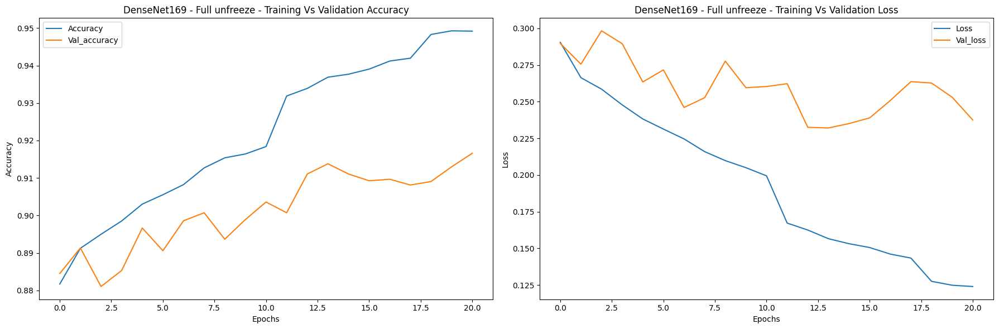

In [ ]:
h_head    = pd.read_csv(project_path / "densenet169_Head_training.csv",    index_col="epoch").to_dict("list")
h_partial = pd.read_csv(project_path / "densenet169_PartialUnfreeze.csv",  index_col="epoch").to_dict("list")
h_full    = pd.read_csv(project_path / "densenet169_FullUnfreeze.csv",     index_col="epoch").to_dict("list")

plot_graphs(h_full, "DenseNet169 - Full unfreeze")
FD_Net.history_all = {k: list(h_head[k]) + list(h_partial[k]) + list(h_full[k]) for k in h_full}


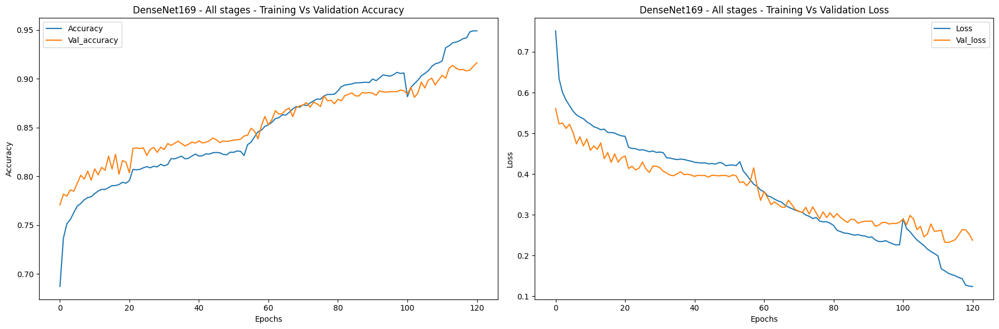

In [ ]:
plot_graphs(FD_Net.history_all, "DenseNet169 - All stages")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.9147 - loss: 0.2238

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 51s 132ms/step
Total inference time: 55.56s for 15000 samples
Mean time per sample: 3.70 ms

---------------------------------------------------------


Correct predictions: 13721 / 15000 --(91.47%) 
Number of correct predictions above 90% confidence  : 11592 --(84.48%) 
Number of correct predictions    80-90% confidence  : 777 --(5.66%) 
Number of correct predictions    70-80% confidence  : 582 --(4.24%) 
Number of correct predictions    50-70% confidence  : 757 --(5.52%) 
Number of correct predictions less  50% confidence  : 13 --(0.09%) 

---------------------------------------------------------


Wrong predictions: 1279 / 15000 --(8.53%) 
Wrong above 90% confidence  : 307 --Band accuracy (97.42%) 
Wrong    80-90% confidence  : 181 --Band accuracy (81.11%) 
Wrong 

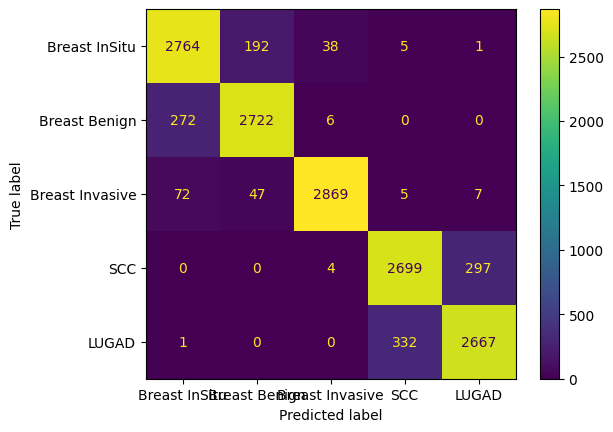

                 precision    recall  f1-score   support

  Breast InSitu       0.89      0.92      0.90      3000
  Breast Benign       0.92      0.91      0.91      3000
Breast Invasive       0.98      0.96      0.97      3000
            SCC       0.89      0.90      0.89      3000
          LUGAD       0.90      0.89      0.89      3000

       accuracy                           0.91     15000
      macro avg       0.92      0.91      0.91     15000
   weighted avg       0.92      0.91      0.91     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9931389750000001 


In [ ]:
FD_Net.evaluate(Densenet_test_generator)

In [61]:
load(FD_Net, "densenet169_FullUnfreeze.keras")

Predicted class: Breast Benign
Probability: 99.9642%
Time: 0.73 Sec
Correct Prediction


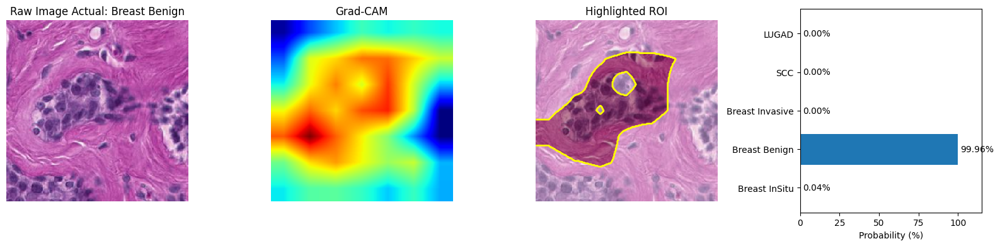

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 100.0000%
Time: 0.73 Sec
Correct Prediction


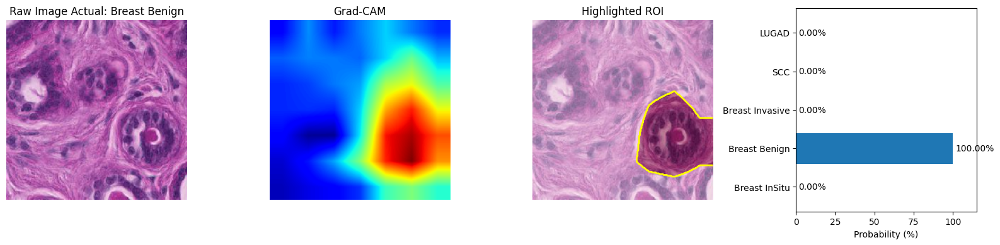

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 78.8792%
Time: 0.73 Sec
Correct Prediction


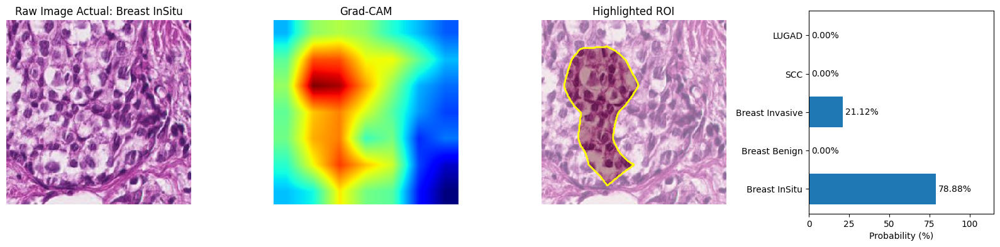

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.5468%
Time: 0.74 Sec
Correct Prediction


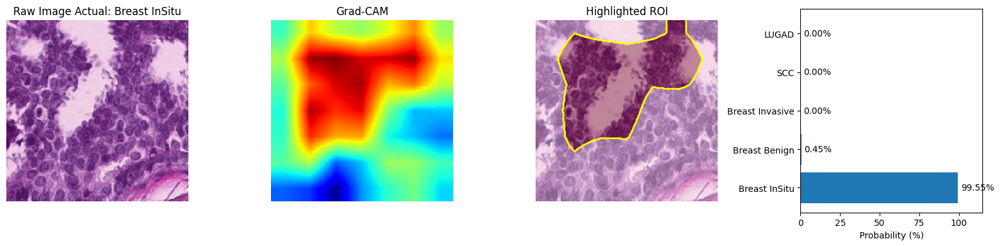

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.74 Sec
Correct Prediction


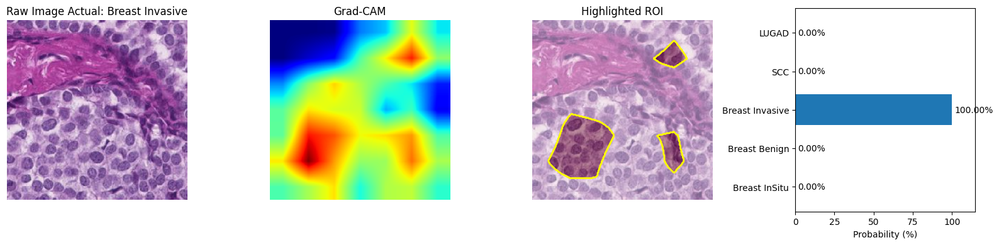

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 99.9997%
Time: 0.75 Sec
Correct Prediction


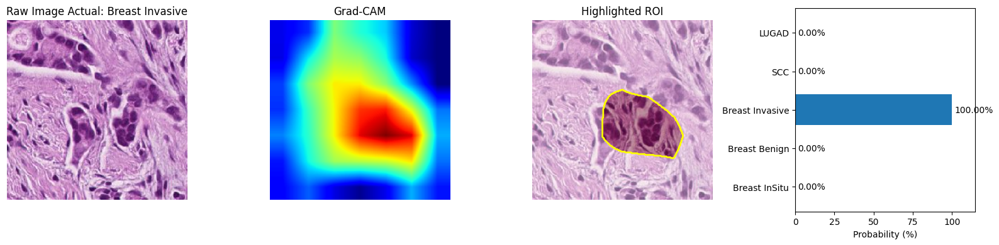

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 99.8405%
Time: 0.74 Sec
Correct Prediction


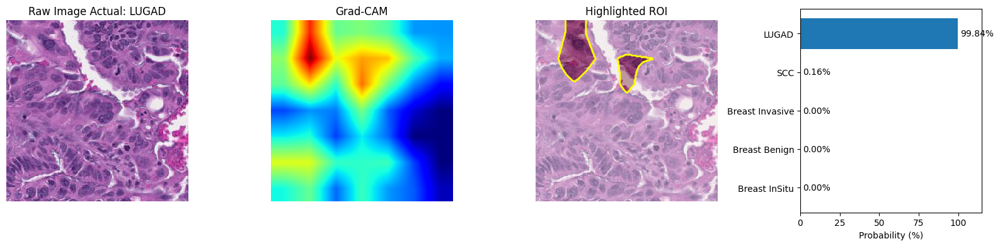

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 75.6587%
Time: 0.73 Sec
Wrong Prediction


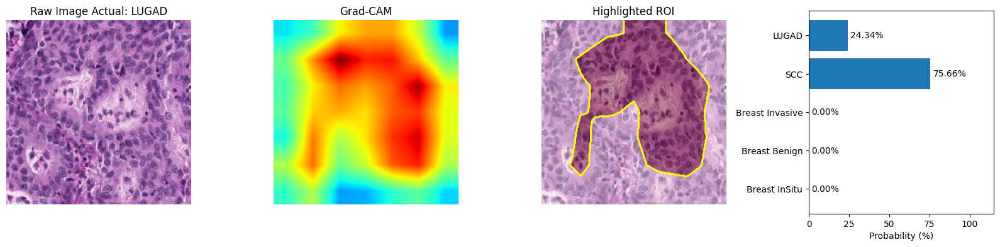

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.9590%
Time: 0.73 Sec
Correct Prediction


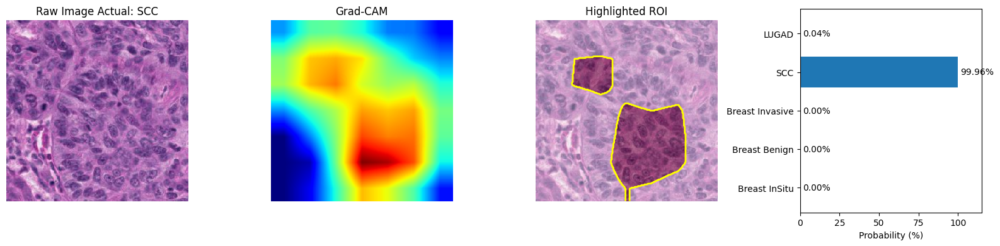

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 98.1551%
Time: 0.73 Sec
Wrong Prediction


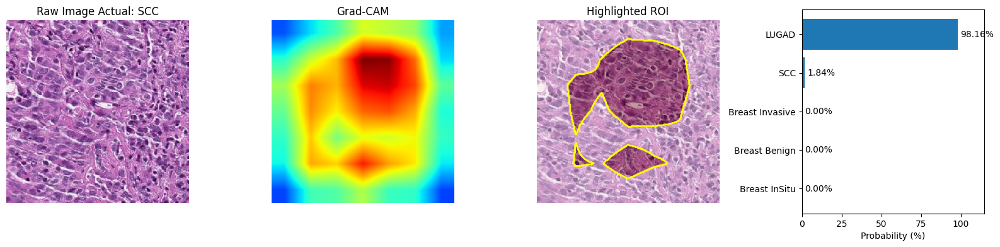

------------------------------------------------------------------------------------------------------------------------------------------------------


In [62]:
for i in range(Num_samples):
  FD_Net.grad_cam(raw_image_path[i], class_name[i], threshold=0.7)
  print("-"*150)

## ### ResNet50V2 - Partial Unfreezing  @ 1e-4 for block 5,  then 1e-5 for full


In [ ]:
# Partial unfreeze : train only the last stage (conv5) of ResNet50V2, with lower learning rate to not affect the backbone
PR_Net =  Build_model (backbone_name= "resnet50v2", dense_layer=256, dropout=0.5)
load (PR_Net, "resnet50v2_Head_training.keras")

file_dis = "resnet50v2_PartialUnfreeze_1e4"
print("----------- Training --------------")

base = PR_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers[0:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False
  elif layer.name.startswith("conv5_"):      # last stage only
    layer.trainable = True
  else:
    layer.trainable = False

PR_Net.model.summary()

# Call Training and get history
PR_Net.history_partial = PR_Net.training(Resnet_train_generator, Resnet_val_generator, file_dis , early_stop_patient= 7, learning_rate = 0.0001, N_Epochs  = 70)


----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,142,293 (95.91 MB)

 Trainable params: 15,476,229 (59.04 MB)

 Non-trainable params: 8,614,400 (32.86 MB)

 Optimizer params: 1,051,664 (4.01 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 217s 183ms/step - accuracy: 0.7957 - loss: 0.5060 - val_accuracy: 0.8283 - val_loss: 0.4255 - learning_rate: 1.0000e-04
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8323 - loss: 0.4107 - val_accuracy: 0.8561 - val_loss: 0.3439 - learning_rate: 1.0000e-04
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 185s 168ms/step - accuracy: 0.8489 - loss: 0.3737 - val_accuracy: 0.8607 - val_loss: 0.3449 - learning_rate: 1.0000e-04
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 185s 168ms/step - accuracy: 0.8563 - loss: 0.3539 - val_accuracy: 0.8609 - val_loss: 0.3512 - learning_rate: 1.0000e-04
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 185s 168ms/step - accuracy: 0.8639 - loss: 0.3321 - val_accuracy: 0.8429 - val_loss: 0.4123 - learning_rate: 1.0000e-04
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.8720 - loss: 0.3164 - val_accuracy: 0.8703 - val_loss: 0.3273 - learning_rate: 1.0000e-04
Epoch 7/70
1094/1094 

In [ ]:
# Save History
PR_Net.save_history(PR_Net.history_partial, file_dis )   # Just Save history as CSV

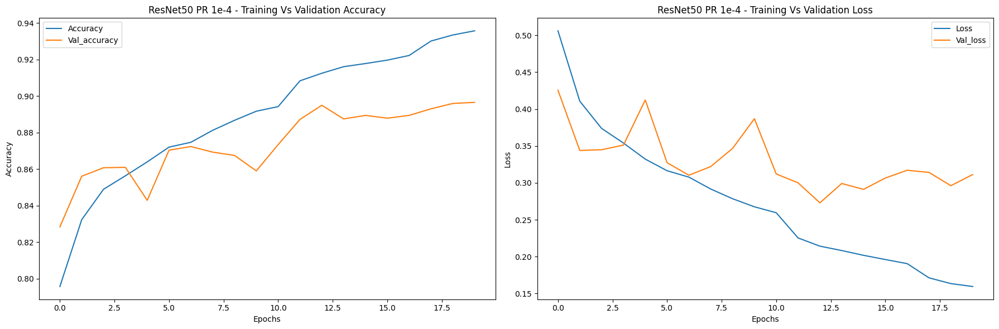

In [ ]:
plot_graphs(PR_Net.history_partial, "ResNet50 PR 1e-4")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.8985 - loss: 0.2604

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step
Total inference time: 20.96s for 15000 samples
Mean time per sample: 1.40 ms

---------------------------------------------------------


Correct predictions: 13478 / 15000 --(89.85%) 
Number of correct predictions above 90% confidence  : 10844 --(80.46%) 
Number of correct predictions    80-90% confidence  : 978 --(7.26%) 
Number of correct predictions    70-80% confidence  : 665 --(4.93%) 
Number of correct predictions    50-70% confidence  : 950 --(7.05%) 
Number of correct predictions less  50% confidence  : 41 --(0.30%) 

---------------------------------------------------------


Wrong predictions: 1522 / 15000 --(10.15%) 
Wrong above 90% confidence  : 305 --Band accuracy (97.26%) 
Wrong    80-90% confidence  : 261 --Band accuracy (78.93%) 
Wrong  

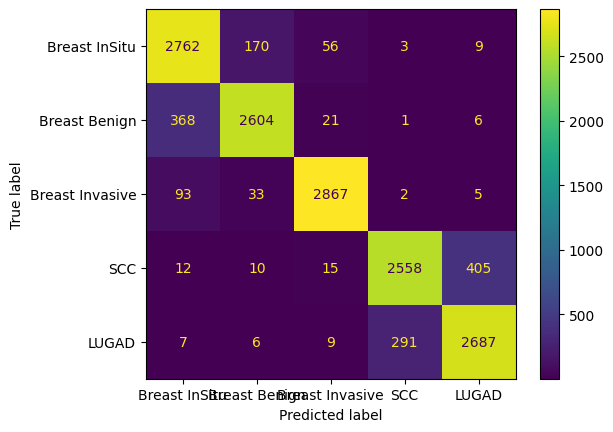

                 precision    recall  f1-score   support

  Breast InSitu       0.85      0.92      0.88      3000
  Breast Benign       0.92      0.87      0.89      3000
Breast Invasive       0.97      0.96      0.96      3000
            SCC       0.90      0.85      0.87      3000
          LUGAD       0.86      0.90      0.88      3000

       accuracy                           0.90     15000
      macro avg       0.90      0.90      0.90     15000
   weighted avg       0.90      0.90      0.90     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9907803916666668 


In [ ]:
# Evaluation
PR_Net.evaluate(Resnet_test_generator)

In [63]:
FR_Net =  Build_model (backbone_name= "resnet50v2", dense_layer=256, dropout=0.5)

In [ ]:
load (FR_Net, "resnet50v2_PartialUnfreeze_1e4.keras")

file_dis = "resnet50v2_GradUnfreeze_1e41e5"
print("----------- Training --------------")

base = FR_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers[0:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False
  else:
    layer.trainable = True

FR_Net.model.summary()


----------- Training --------------


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,043,093 (209.97 MB)

 Trainable params: 23,999,749 (91.55 MB)

 Non-trainable params: 90,880 (355.00 KB)

 Optimizer params: 30,952,464 (118.07 MB)

In [ ]:
FR_Net.history_full = FR_Net.training(Resnet_train_generator, Resnet_val_generator, file_dis , early_stop_patient= 7, learning_rate = 0.00001, N_Epochs  = 70)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 240s 191ms/step - accuracy: 0.9155 - loss: 0.2089 - val_accuracy: 0.8967 - val_loss: 0.2844 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.9181 - loss: 0.2000 - val_accuracy: 0.8931 - val_loss: 0.2962 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.9211 - loss: 0.1914 - val_accuracy: 0.8941 - val_loss: 0.2863 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.9253 - loss: 0.1815 - val_accuracy: 0.8955 - val_loss: 0.2992 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 186s 168ms/step - accuracy: 0.9273 - loss: 0.1799 - val_accuracy: 0.8939 - val_loss: 0.3049 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 187s 169ms/step - accuracy: 0.9350 - loss: 0.1608 - val_accuracy: 0.9014 - val_loss: 0.2748 - learning_rate: 5.0000e-06
Epoch 7/70
1094/1094 

In [ ]:
FR_Net.save_history(FR_Net.history_full, file_dis)

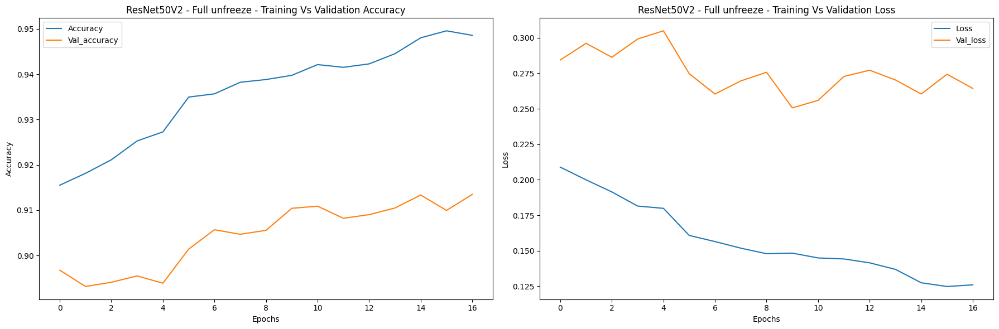

In [ ]:
h_head    = pd.read_csv(project_path / "resnet50v2_Head_training.csv",   index_col="epoch").to_dict("list")
h_partial = pd.read_csv(project_path / "resnet50v2_PartialUnfreeze_1e4.csv", index_col="epoch").to_dict("list")
h_full    = pd.read_csv(project_path / "resnet50v2_GradUnfreeze_1e41e5.csv",    index_col="epoch").to_dict("list")

plot_graphs(h_full,    "ResNet50V2 - Full unfreeze")
FR_Net.history_all = {k: list(h_head[k]) + list(h_partial[k]) + list(h_full[k]) for k in h_full}


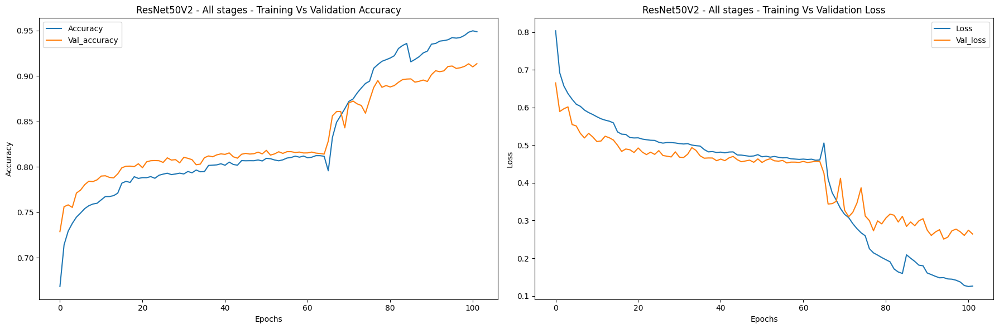

In [ ]:
plot_graphs(FR_Net.history_all, "ResNet50V2 - All stages")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.9139 - loss: 0.2340

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step
Total inference time: 21.04s for 15000 samples
Mean time per sample: 1.40 ms

---------------------------------------------------------


Correct predictions: 13708 / 15000 --(91.39%) 
Number of correct predictions above 90% confidence  : 11728 --(85.56%) 
Number of correct predictions    80-90% confidence  : 782 --(5.70%) 
Number of correct predictions    70-80% confidence  : 479 --(3.49%) 
Number of correct predictions    50-70% confidence  : 697 --(5.08%) 
Number of correct predictions less  50% confidence  : 22 --(0.16%) 

---------------------------------------------------------


Wrong predictions: 1292 / 15000 --(8.61%) 
Wrong above 90% confidence  : 345 --Band accuracy (97.14%) 
Wrong    80-90% confidence  : 182 --Band accuracy (81.12%) 
Wrong   

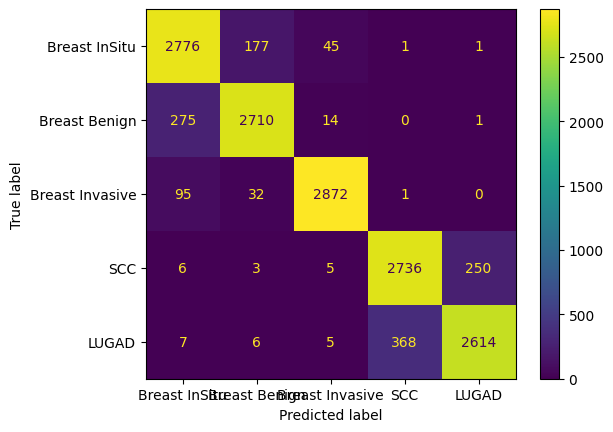

                 precision    recall  f1-score   support

  Breast InSitu       0.88      0.93      0.90      3000
  Breast Benign       0.93      0.90      0.91      3000
Breast Invasive       0.98      0.96      0.97      3000
            SCC       0.88      0.91      0.90      3000
          LUGAD       0.91      0.87      0.89      3000

       accuracy                           0.91     15000
      macro avg       0.91      0.91      0.91     15000
   weighted avg       0.91      0.91      0.91     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9928393583333334 


In [ ]:
# load(FR_Net, "resnet50v2_FullUnfreeze.keras")
FR_Net.evaluate(Resnet_test_generator)

In [64]:
load(FR_Net, "resnet50v2_GradUnfreeze_1e41e5.keras")

Predicted class: Breast Benign
Probability: 100.0000%
Time: 0.26 Sec
Correct Prediction


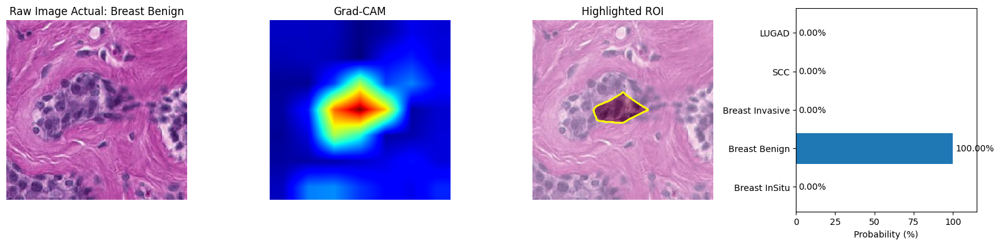

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 99.9992%
Time: 0.26 Sec
Correct Prediction


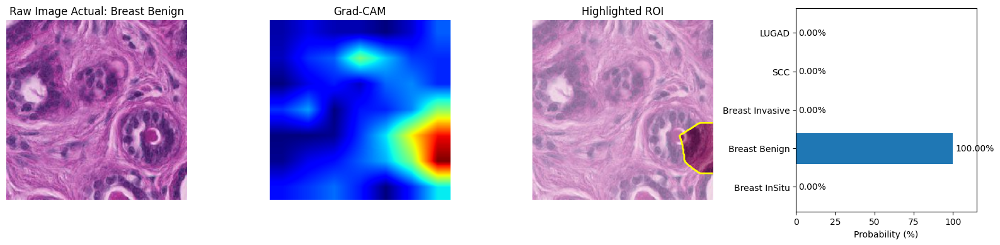

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9249%
Time: 0.26 Sec
Correct Prediction


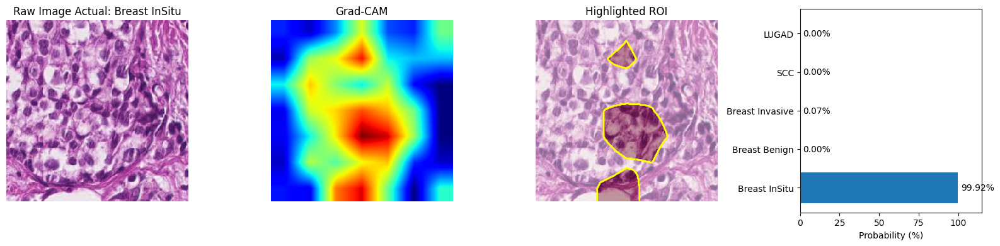

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 100.0000%
Time: 0.27 Sec
Correct Prediction


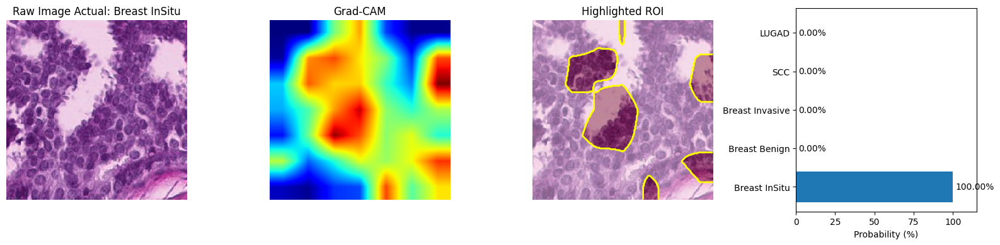

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.26 Sec
Correct Prediction


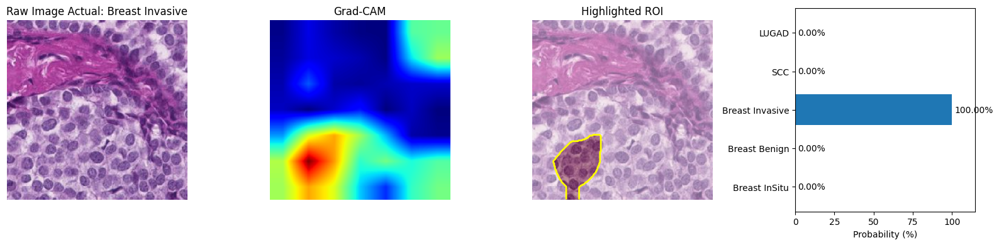

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.27 Sec
Correct Prediction


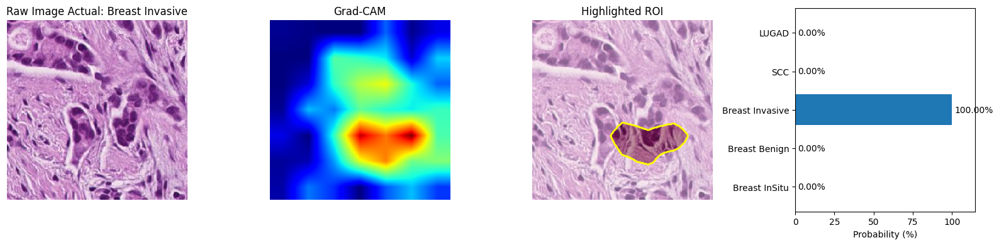

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 99.9969%
Time: 0.26 Sec
Correct Prediction


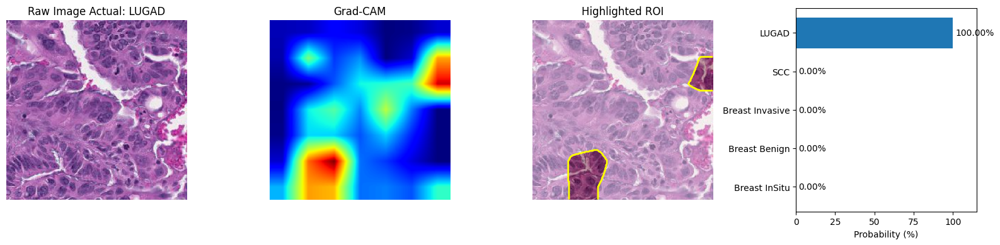

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.8972%
Time: 0.26 Sec
Wrong Prediction


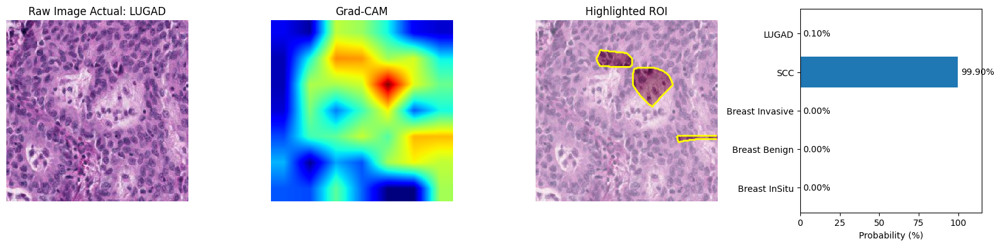

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.9901%
Time: 0.28 Sec
Correct Prediction


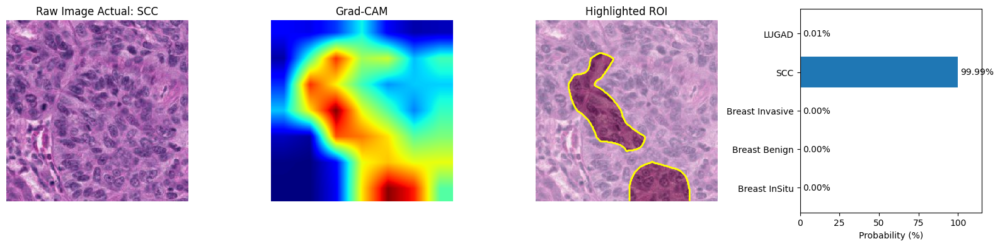

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 74.2749%
Time: 0.28 Sec
Wrong Prediction


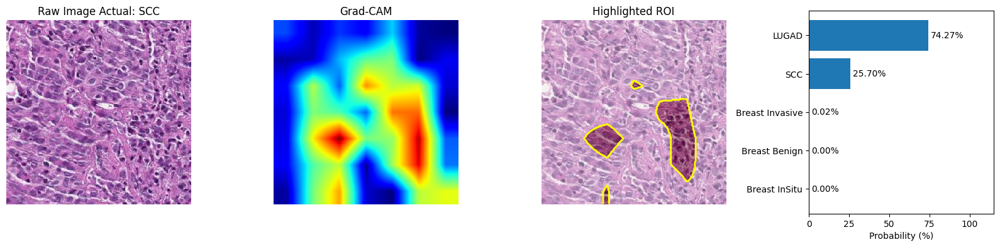

------------------------------------------------------------------------------------------------------------------------------------------------------


In [65]:
for i in range(Num_samples):
  FR_Net.grad_cam(raw_image_path[i],class_name[i], threshold=0.7)
  print("-"*150)

## DenseNet169 - Partial Unfreezing @ 1e-4 for block 5 then 1e-5

In [ ]:
# Partial unfreeze : train only the last dense block (conv5) of DenseNet169, with lower learning rate to not affect the backbone
PD_Net =  Build_model (backbone_name= "densenet169", dense_layer=256, dropout=0.5)
load (PD_Net, "densenet169_Head_training.keras")

file_dis = "densenet169_PartialUnfreeze_1e4"
print("----------- Training --------------")

base = PD_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers[0:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False
  elif layer.name.startswith("conv5_"):      # last dense block only
    layer.trainable = True
  else:
    layer.trainable = False

PD_Net.model.summary()

# Call Training and get history
PD_Net.history_partial = PD_Net.training(Densenet_train_generator, Densenet_val_generator, file_dis , early_stop_patient= 7, learning_rate = 0.0001, N_Epochs  = 70)



----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,925,461 (53.12 MB)

 Trainable params: 6,260,229 (23.88 MB)

 Non-trainable params: 6,810,176 (25.98 MB)

 Optimizer params: 855,056 (3.26 MB)

/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 339s 249ms/step - accuracy: 0.7872 - loss: 0.5202 - val_accuracy: 0.8371 - val_loss: 0.3968 - learning_rate: 1.0000e-04
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 204s 185ms/step - accuracy: 0.8179 - loss: 0.4408 - val_accuracy: 0.8475 - val_loss: 0.3952 - learning_rate: 1.0000e-04
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 205s 185ms/step - accuracy: 0.8326 - loss: 0.4051 - val_accuracy: 0.8602 - val_loss: 0.3453 - learning_rate: 1.0000e-04
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 204s 185ms/step - accuracy: 0.8414 - loss: 0.3885 - val_accuracy: 0.8483 - val_loss: 0.3608 - learning_rate: 1.0000e-04
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 204s 185ms/step - accuracy: 0.8504 - loss: 0.3694 - val_accuracy: 0.8583 - val_loss: 0.3587 - learning_rate: 1.0000e-04
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 204s 185ms/step - accuracy: 0.8569 - loss: 0.3506 - val_accuracy: 0.8491 - val_loss: 0.3666 - learning_rate: 1.0000e-04
Epoch 7/70
1094/1094 

In [ ]:
# Save History
PD_Net.save_history(PD_Net.history_partial, file_dis )   # Just Save history as CSV

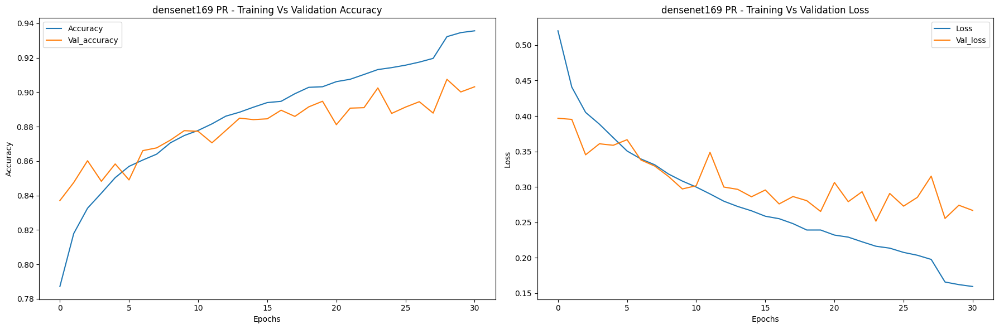

In [ ]:
plot_graphs(PD_Net.history_partial, "densenet169 PR")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - accuracy: 0.9044 - loss: 0.2461

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 53s 139ms/step
Total inference time: 57.51s for 15000 samples
Mean time per sample: 3.83 ms

---------------------------------------------------------


Correct predictions: 13566 / 15000 --(90.44%) 
Number of correct predictions above 90% confidence  : 11044 --(81.41%) 
Number of correct predictions    80-90% confidence  : 956 --(7.05%) 
Number of correct predictions    70-80% confidence  : 640 --(4.72%) 
Number of correct predictions    50-70% confidence  : 899 --(6.63%) 
Number of correct predictions less  50% confidence  : 27 --(0.20%) 

---------------------------------------------------------


Wrong predictions: 1434 / 15000 --(9.56%) 
Wrong above 90% confidence  : 302 --Band accuracy (97.34%) 
Wrong    80-90% confidence  : 201 --Band accuracy (82.63%) 
Wrong 

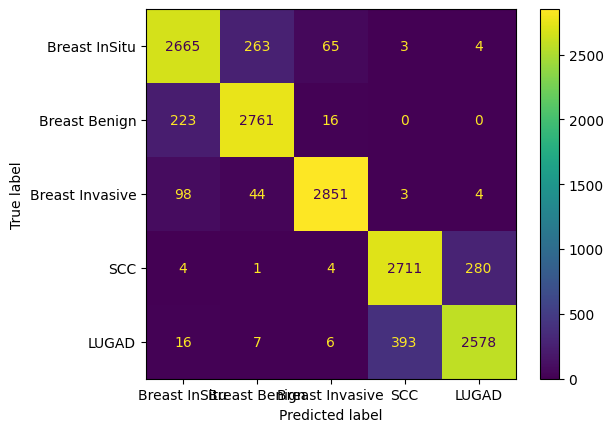

                 precision    recall  f1-score   support

  Breast InSitu       0.89      0.89      0.89      3000
  Breast Benign       0.90      0.92      0.91      3000
Breast Invasive       0.97      0.95      0.96      3000
            SCC       0.87      0.90      0.89      3000
          LUGAD       0.90      0.86      0.88      3000

       accuracy                           0.90     15000
      macro avg       0.90      0.90      0.90     15000
   weighted avg       0.90      0.90      0.90     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9914917694444444 


In [ ]:
# Evaluation
PD_Net.evaluate(Densenet_test_generator)

In [66]:
FD_Net = Build_model(backbone_name="densenet169", dense_layer=256, dropout=0.5)

In [19]:
load(FD_Net, "densenet169_PartialUnfreeze_1e4.keras")

file_dis = "densenet169_GradUnfreeze_1e41e5"
print("----------- Training --------------")

base = FD_Net.model.layers[1]         # The backbone
base.trainable = True
for layer in base.layers:
  layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

FD_Net.model.summary()


----------- Training --------------


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,070,405 (49.86 MB)

 Trainable params: 12,753,605 (48.65 MB)

 Non-trainable params: 316,800 (1.21 MB)

In [20]:
FD_Net.history_full = FD_Net.training(Densenet_train_generator, Densenet_val_generator, file_dis, early_stop_patient=7, learning_rate=0.00001, N_Epochs=70)


/GPU:0
Epoch 1/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 399s 286ms/step - accuracy: 0.9161 - loss: 0.2104 - val_accuracy: 0.9067 - val_loss: 0.2396 - learning_rate: 1.0000e-05
Epoch 2/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 202s 183ms/step - accuracy: 0.9251 - loss: 0.1851 - val_accuracy: 0.8975 - val_loss: 0.2691 - learning_rate: 1.0000e-05
Epoch 3/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 202s 182ms/step - accuracy: 0.9296 - loss: 0.1784 - val_accuracy: 0.8982 - val_loss: 0.2791 - learning_rate: 1.0000e-05
Epoch 4/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 201s 182ms/step - accuracy: 0.9317 - loss: 0.1697 - val_accuracy: 0.9051 - val_loss: 0.2614 - learning_rate: 1.0000e-05
Epoch 5/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 202s 182ms/step - accuracy: 0.9327 - loss: 0.1639 - val_accuracy: 0.9075 - val_loss: 0.2324 - learning_rate: 1.0000e-05
Epoch 6/70
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 202s 182ms/step - accuracy: 0.9362 - loss: 0.1610 - val_accuracy: 0.9089 - val_loss: 0.2460 - learning_rate: 1.0000e-05
Epoch 7/70
1094/1094 

In [21]:
FD_Net.save_history(FD_Net.history_full, file_dis)

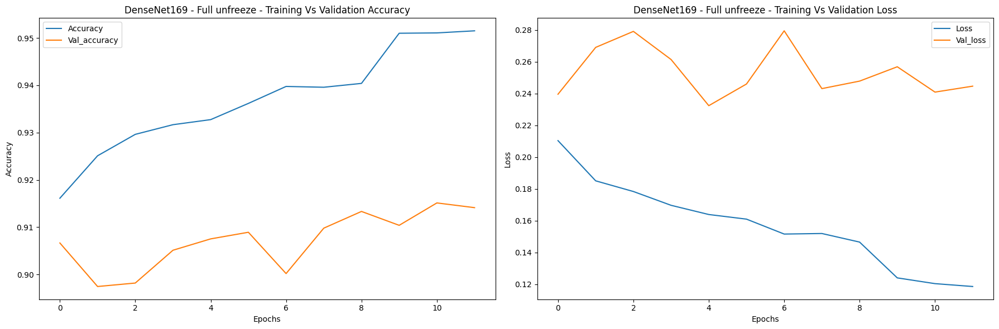

In [22]:
h_head    = pd.read_csv(project_path / "densenet169_PartialUnfreeze_1e4.csv",    index_col="epoch").to_dict("list")
h_partial = pd.read_csv(project_path / "densenet169_PartialUnfreeze.csv",  index_col="epoch").to_dict("list")
h_full    = pd.read_csv(project_path / "densenet169_GradUnfreeze_1e41e5.csv",     index_col="epoch").to_dict("list")

plot_graphs(h_full, "DenseNet169 - Full unfreeze")
FD_Net.history_all = {k: list(h_head[k]) + list(h_partial[k]) + list(h_full[k]) for k in h_full}


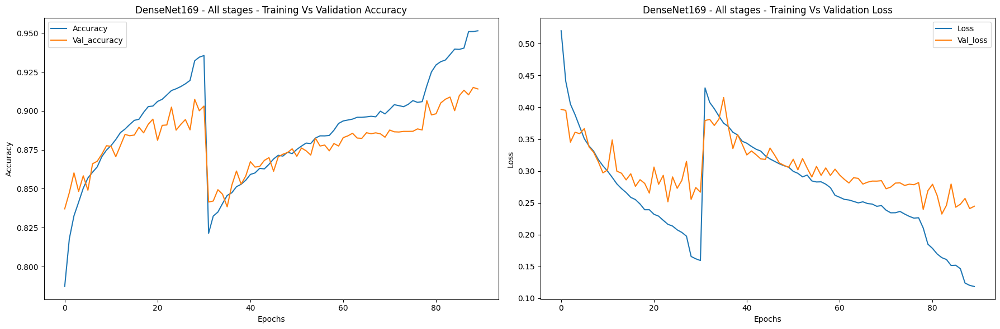

In [23]:
plot_graphs(FD_Net.history_all, "DenseNet169 - All stages")

 MODEL EVALUATION
  Model Accuracy for Testing Set = 
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.9159 - loss: 0.2231

---------------------------------------------------------  


235/235 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step
Total inference time: 53.19s for 15000 samples
Mean time per sample: 3.55 ms

---------------------------------------------------------


Correct predictions: 13738 / 15000 --(91.59%) 
Number of correct predictions above 90% confidence  : 11523 --(83.88%) 
Number of correct predictions    80-90% confidence  : 864 --(6.29%) 
Number of correct predictions    70-80% confidence  : 580 --(4.22%) 
Number of correct predictions    50-70% confidence  : 747 --(5.44%) 
Number of correct predictions less  50% confidence  : 24 --(0.17%) 

---------------------------------------------------------


Wrong predictions: 1262 / 15000 --(8.41%) 
Wrong above 90% confidence  : 295 --Band accuracy (97.50%) 
Wrong    80-90% confidence  : 201 --Band accuracy (81.13%) 
Wrong  

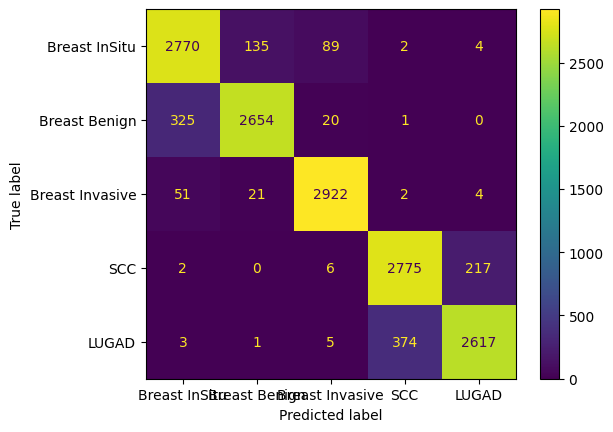

                 precision    recall  f1-score   support

  Breast InSitu       0.88      0.92      0.90      3000
  Breast Benign       0.94      0.88      0.91      3000
Breast Invasive       0.96      0.97      0.97      3000
            SCC       0.88      0.93      0.90      3000
          LUGAD       0.92      0.87      0.90      3000

       accuracy                           0.92     15000
      macro avg       0.92      0.92      0.92     15000
   weighted avg       0.92      0.92      0.92     15000


---------------------------------------------------------  


Macro_roc_auc = 0.9932081666666667 


In [24]:
FD_Net.evaluate(Densenet_test_generator)

In [67]:
load(FD_Net, "densenet169_GradUnfreeze_1e41e5.keras")

Predicted class: Breast Benign
Probability: 99.9739%
Time: 0.74 Sec
Correct Prediction


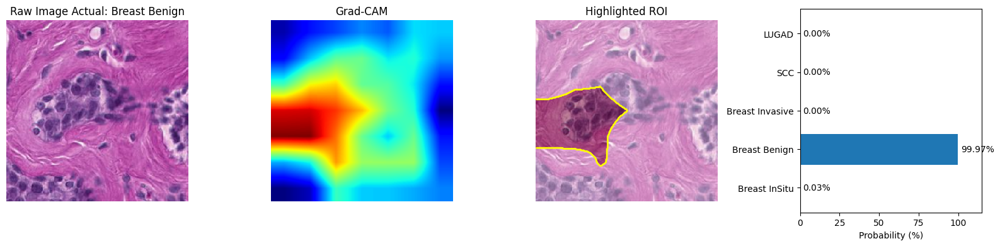

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Benign
Probability: 99.9999%
Time: 0.75 Sec
Correct Prediction


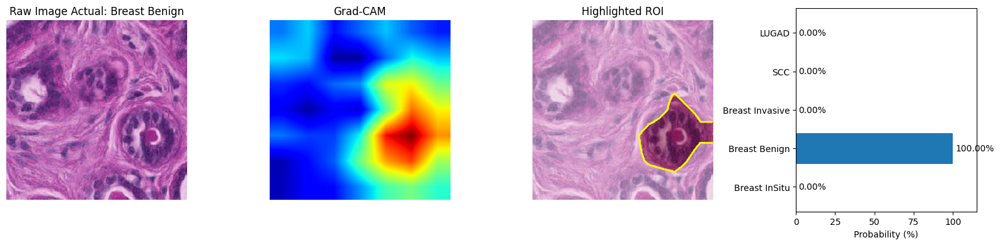

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 66.4468%
Time: 0.73 Sec
Wrong Prediction


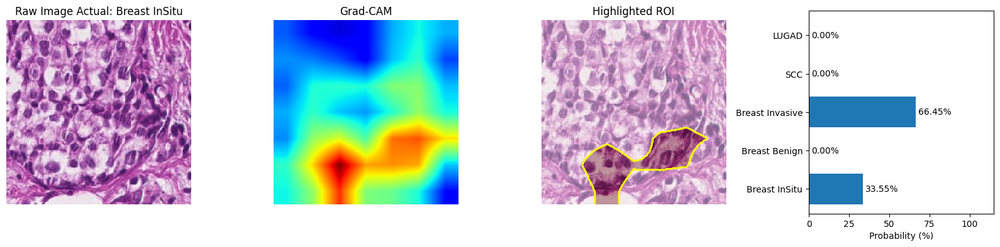

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast InSitu
Probability: 99.9944%
Time: 0.74 Sec
Correct Prediction


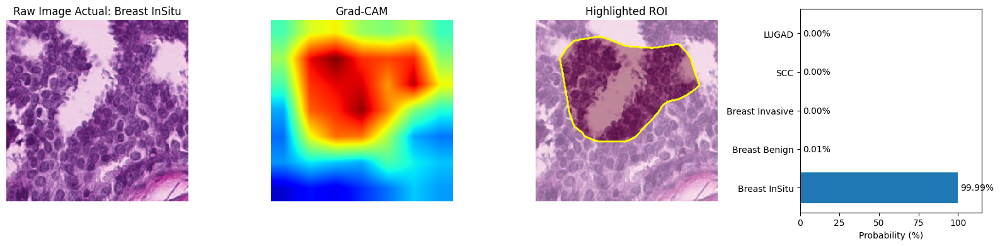

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.74 Sec
Correct Prediction


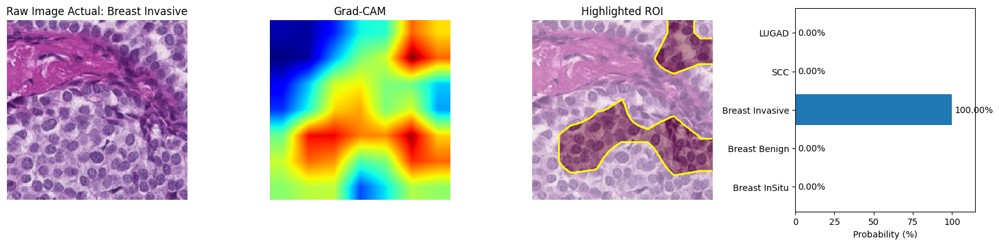

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: Breast Invasive
Probability: 100.0000%
Time: 0.74 Sec
Correct Prediction


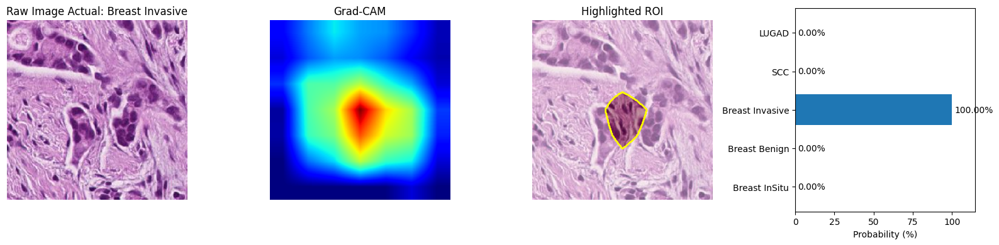

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 98.7677%
Time: 0.74 Sec
Correct Prediction


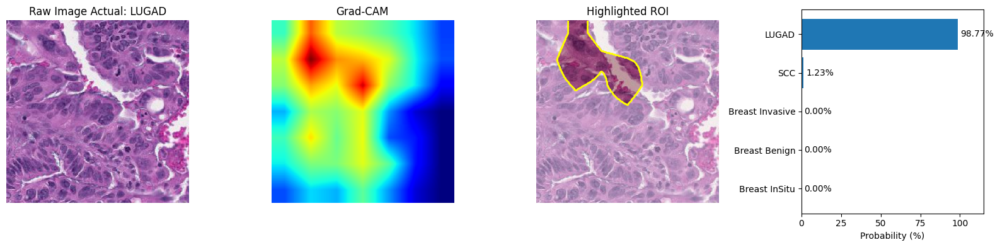

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 80.9132%
Time: 0.74 Sec
Wrong Prediction


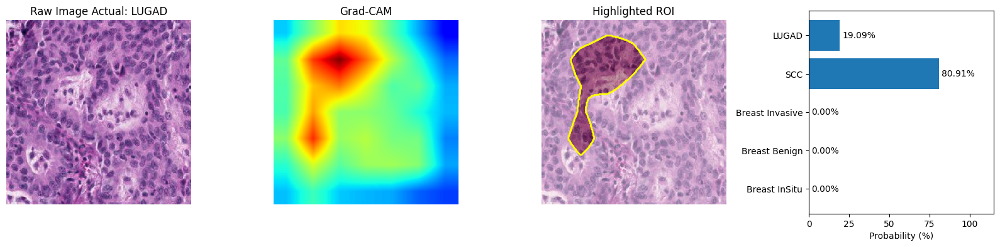

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: SCC
Probability: 99.6394%
Time: 0.73 Sec
Correct Prediction


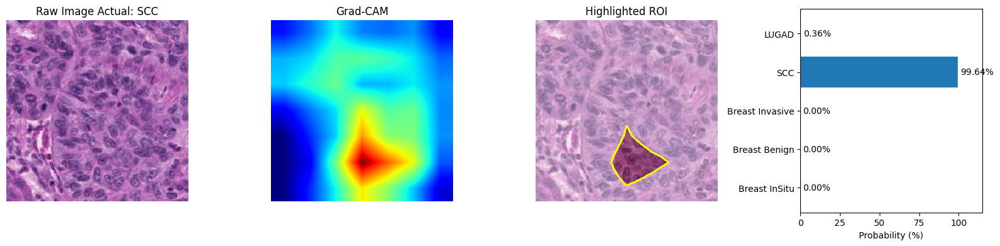

------------------------------------------------------------------------------------------------------------------------------------------------------
Predicted class: LUGAD
Probability: 98.8406%
Time: 0.74 Sec
Wrong Prediction


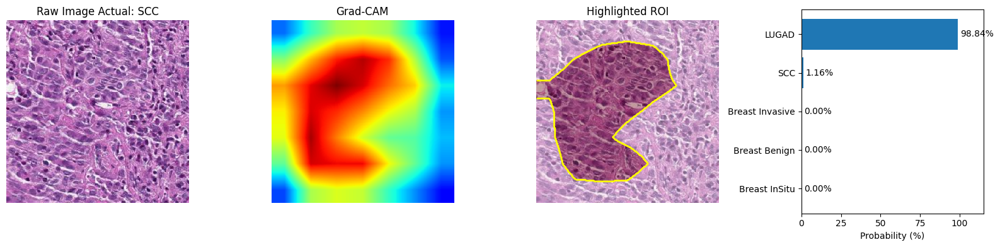

------------------------------------------------------------------------------------------------------------------------------------------------------


In [68]:
for i in range(Num_samples):
  FD_Net.grad_cam(raw_image_path[i], class_name[i], threshold=0.7)
  print("-"*150)